In [1]:
#@title Configure { display-mode: "form" }

#@markdown Folder **in Drive** holding the two archives:
ARCHIVE_DIR = "/content/drive/MyDrive/DriveJEPA_NuScenes/01_Raw_Dataset"  #@param {type:"string"}

#@markdown Where to extract (Colab local disk — fast, wiped on disconnect):
DATAROOT = "/content/nuscenes"  #@param {type:"string"}

VERSION = "v1.0-mini"  #@param ["v1.0-mini", "v1.0-trainval"]

#@markdown Untick if you already extracted in this session:
DO_EXTRACT = True  #@param {type:"boolean"}

import os, time
from google.colab import drive
drive.mount('/content/drive')

print(f"\narchives : {ARCHIVE_DIR}")
if os.path.isdir(ARCHIVE_DIR):
    for f in sorted(os.listdir(ARCHIVE_DIR)):
        sz = os.path.getsize(os.path.join(ARCHIVE_DIR, f)) / 1e9
        print(f"           {f}  ({sz:.2f} GB)")
else:
    print("           NOT FOUND — fix ARCHIVE_DIR above")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

archives : /content/drive/MyDrive/DriveJEPA_NuScenes/01_Raw_Dataset
           can_bus.zip  (0.78 GB)
           v1.0-mini.tgz  (4.17 GB)


In [2]:
import os
print(os.listdir("/content/drive/MyDrive/DriveJEPA"))

['smoke_frames_72x128.npz', 'jepa_v1_step26.pt', 'jepa_v2_step29.pt', 'jepa_v3_step30.pt', 'jepa_v4_step31.pt', 'jepa_v5_step34.pt', 'drivejepa_full_dataset', 'drivejepa_full_dataset_sigreg', 'drivejepa_final_sigreg', 'drivejepa_stage2_evaluation', 'nuScenes']


In [3]:
import os

dataset_dir = "/content/drive/MyDrive/DriveJEPA/nuScenes"
os.makedirs(dataset_dir, exist_ok=True)

print("Dataset folder ready:", dataset_dir)

Dataset folder ready: /content/drive/MyDrive/DriveJEPA/nuScenes


In [4]:
import os

file_path = "/content/drive/MyDrive/DriveJEPA_NuScenes/01_Raw_Dataset/v1.0-mini.tgz"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size (GB):", round(os.path.getsize(file_path) / 1e9, 2))

File exists: True
File size (GB): 4.17


In [5]:
import os

drivejepa_dir = "/content/drive/MyDrive/DriveJEPA_NuScenes/01_Raw_Dataset"

for filename in ["v1.0-mini.tgz", "can_bus.zip"]:
    path = os.path.join(drivejepa_dir, filename)
    print(f"{filename}:")
    print("  Exists:", os.path.exists(path))
    if os.path.exists(path):
        print("  Size (MB):", round(os.path.getsize(path) / 1e6, 2))

v1.0-mini.tgz:
  Exists: True
  Size (MB): 4168.15
can_bus.zip:
  Exists: True
  Size (MB): 780.97


In [6]:
import os

extract_path = "/content/nuscenes"

if os.path.exists(extract_path):
    print("Extracted folders:", os.listdir(extract_path))
else:
    print("Dataset not extracted yet")

Extracted folders: ['.v1.0-mini.txt', 'maps', 'v1.0-mini', 'samples', 'can_bus', 'LICENSE', 'sweeps']


In [7]:
#@title Extract to local disk (~1–2 min)

# Your Google Drive paths
ARCHIVE_DIR = "/content/drive/MyDrive/DriveJEPA_NuScenes/01_Raw_Dataset"
DATAROOT = "/content/nuscenes"
VERSION = "v1.0-mini"

if DO_EXTRACT:
    os.makedirs(DATAROOT, exist_ok=True)
    t0 = time.time()

    # Copy off Drive first — extracting straight from a Drive path is far slower.
    print("copying archives to local disk...")
    !cp "{ARCHIVE_DIR}/v1.0-mini.tgz" /content/
    !cp "{ARCHIVE_DIR}/can_bus.zip" /content/

    print("extracting v1.0-mini.tgz...")
    !tar -xzf /content/v1.0-mini.tgz -C "{DATAROOT}"

    print("extracting can_bus.zip...")
    !unzip -q -o /content/can_bus.zip -d "{DATAROOT}"

    # Free local archive storage — originals remain in Drive.
    !rm -f /content/v1.0-mini.tgz /content/can_bus.zip

    print(f"\ndone in {time.time() - t0:.0f}s")

print("\ncontents of DATAROOT:")
for d in sorted(os.listdir(DATAROOT)):
    print(f"  {d}")

n_tables = len([
    f for f in os.listdir(f"{DATAROOT}/{VERSION}")
    if f.endswith('.json')
])

print(f"\nmetadata tables: {n_tables} (13 = correct base set; 2–3 = expansion)")

copying archives to local disk...
extracting v1.0-mini.tgz...
extracting can_bus.zip...

done in 166s

contents of DATAROOT:
  .v1.0-mini.txt
  LICENSE
  can_bus
  maps
  samples
  sweeps
  v1.0-mini

metadata tables: 13 (13 = correct base set; 2–3 = expansion)


In [8]:
#@title Extract to local disk  (~1–2 min)

if DO_EXTRACT:
    os.makedirs(DATAROOT, exist_ok=True)
    t0 = time.time()

    # Copy off Drive first — extracting straight from a Drive path is far slower.
    print("copying archives to local disk...")
    !cp "{ARCHIVE_DIR}/v1.0-mini.tgz" /content/ 2>/dev/null
    !cp "{ARCHIVE_DIR}/can_bus.zip"   /content/ 2>/dev/null

    print("extracting v1.0-mini.tgz...")
    !tar -xzf /content/v1.0-mini.tgz -C "{DATAROOT}"

    print("extracting can_bus.zip...")
    !unzip -q -o /content/can_bus.zip -d "{DATAROOT}"

    # Free ~5 GB — the archives are still in Drive.
    !rm -f /content/v1.0-mini.tgz /content/can_bus.zip
    print(f"\ndone in {time.time() - t0:.0f}s")

print("\ncontents of DATAROOT:")
for d in sorted(os.listdir(DATAROOT)):
    print(f"  {d}")

n_tables = len([f for f in os.listdir(f"{DATAROOT}/{VERSION}") if f.endswith('.json')])
print(f"\nmetadata tables: {n_tables}   (13 = correct base set; 2–3 = you grabbed an expansion)")

copying archives to local disk...
extracting v1.0-mini.tgz...
extracting can_bus.zip...

done in 171s

contents of DATAROOT:
  .v1.0-mini.txt
  LICENSE
  can_bus
  maps
  samples
  sweeps
  v1.0-mini

metadata tables: 13   (13 = correct base set; 2–3 = you grabbed an expansion)


In [9]:
#@title Install the devkit
!pip install -q nuscenes-devkit
print("ok")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
spopt 0.7.0 requires shapely>=2.1.0, but you have shapely 2.0.7 which is incompatible.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
esda 2.9.0 requires shapely>=2.1, but you have shapely 2.0.7 which is incompatible.
opencv-contrib-python 4.14.0.94 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
pointpats 2.5.5 requires shapely>=2.1, but you have shapely 2.0.7 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.4 which is incompatible.
geopandas 1.2.0 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
geopandas 1.2.0 requires shapely>=2.1.0, but you have shapely 2.0.7 which is incompatible.
dm-tree 0.1.10 requires numpy>=2.1.0; python_version >= "3.13", b

In [10]:
!pip install -q --no-deps nuscenes-devkit
!pip install -q pyquaternion cachetools descartes

In [11]:
!pip install -q "numpy==1.26.4" "Shapely==2.0.7" fire parameterized

In [13]:
import numpy as np
import shapely

print("NumPy:", np.__version__)
print("Shapely:", shapely.__version__)

from nuscenes.nuscenes import NuScenes
from nuscenes.can_bus.can_bus_api import NuScenesCanBus

print("nuScenes imports successful!")

NumPy: 2.2.6
Shapely: 2.0.7
nuScenes imports successful!


In [14]:
import os

DATAROOT = "/content/nuscenes"

print("Dataset exists:", os.path.isdir(DATAROOT))
print("Folders:", os.listdir(DATAROOT) if os.path.isdir(DATAROOT) else "Not found")

Dataset exists: True
Folders: ['.v1.0-mini.txt', 'maps', 'v1.0-mini', 'samples', 'can_bus', 'LICENSE', 'sweeps']


In [15]:
VERSION = "v1.0-mini"
DATAROOT = "/content/nuscenes"

import numpy as np, shapely
from nuscenes.nuscenes import NuScenes
from nuscenes.can_bus.can_bus_api import NuScenesCanBus
print("numpy", np.__version__, "| shapely", shapely.__version__)

nusc = NuScenes(version=VERSION, dataroot=DATAROOT, verbose=False)
can  = NuScenesCanBus(dataroot=DATAROOT)
s = nusc.scene[0]
print("scenes", len(nusc.scene), "| samples", len(nusc.sample))
print("CAN msgs", len(can.get_messages(s["name"], "vehicle_monitor")))
print("PASS")

numpy 2.2.6 | shapely 2.0.7
scenes 10 | samples 404
CAN msgs 38
PASS


In [16]:
#@title 1 · Footprint — files, not gigabytes

from collections import Counter

n_files, n_bytes, per_dir = 0, 0, Counter()
for dirpath, _, filenames in os.walk(DATAROOT):
    n_files += len(filenames)
    top = os.path.relpath(dirpath, DATAROOT).split(os.sep)[0]
    per_dir[top] += len(filenames)
    for f in filenames:
        try:
            n_bytes += os.path.getsize(os.path.join(dirpath, f))
        except OSError:
            pass

print(f"total files : {n_files:,}")
print(f"total size  : {n_bytes / 1e9:.2f} GB\n")
for d, c in per_dir.most_common():
    print(f"  {d:<16} {c:>8,} files")

print(f"\nScaling note: mini is 10 of 1000 scenes. Full trainval is roughly")
print(f"{n_files * 85:,.0f} files by this ratio — against a 250,000 file quota on")
print("HPRC scratch. Shard into tar/webdataset before moving past mini.")

total files : 39,057
total size  : 10.01 GB

  sweeps             26,358 files
  can_bus             7,832 files
  samples             4,848 files
  v1.0-mini              13 files
  maps                    4 files
  .                       2 files

Scaling note: mini is 10 of 1000 scenes. Full trainval is roughly
3,319,845 files by this ratio — against a 250,000 file quota on
HPRC scratch. Shard into tar/webdataset before moving past mini.


In [17]:
#@title 2 · Structure

from nuscenes.nuscenes import NuScenes
nusc = NuScenes(version=VERSION, dataroot=DATAROOT, verbose=False)

print(f"scenes      : {len(nusc.scene)}")
print(f"samples     : {len(nusc.sample)}        annotated keyframes @ 2 Hz")
print(f"sample_data : {len(nusc.sample_data):,}      every reading, sweeps included")
print(f"annotations : {len(nusc.sample_annotation):,}\n")

ch = Counter(
    nusc.get("sensor", nusc.get("calibrated_sensor",
             sd["calibrated_sensor_token"])["sensor_token"])["channel"]
    for sd in nusc.sample_data
)
for c, n in sorted(ch.items(), key=lambda kv: -kv[1]):
    print(f"  {c:<24} {n:>7,}")


scenes      : 10
samples     : 404        annotated keyframes @ 2 Hz
sample_data : 31,206      every reading, sweeps included
annotations : 18,538

  LIDAR_TOP                  3,935
  RADAR_FRONT_LEFT           2,686
  RADAR_FRONT_RIGHT          2,673
  RADAR_FRONT                2,635
  RADAR_BACK_RIGHT           2,635
  RADAR_BACK_LEFT            2,634
  CAM_FRONT_LEFT             2,344
  CAM_FRONT                  2,342
  CAM_BACK_RIGHT             2,342
  CAM_FRONT_RIGHT            2,338
  CAM_BACK_LEFT              2,327
  CAM_BACK                   2,315


In [18]:
#@title 3 · One scene

scene = nusc.scene[0]
first = nusc.get("sample", scene["first_sample_token"])
last  = nusc.get("sample", scene["last_sample_token"])
dur   = (last["timestamp"] - first["timestamp"]) / 1e6

print(f"name        : {scene['name']}")
print(f"description : {scene['description']}")
print(f"keyframes   : {scene['nbr_samples']}")
print(f"duration    : {dur:.1f}s  ({scene['nbr_samples']/dur:.2f} Hz)\n")
for c in first["data"]:
    print(f"  {c}")

name        : scene-0061
description : Parked truck, construction, intersection, turn left, following a van
keyframes   : 39
duration    : 19.1s  (2.04 Hz)

  RADAR_FRONT
  RADAR_FRONT_LEFT
  RADAR_FRONT_RIGHT
  RADAR_BACK_LEFT
  RADAR_BACK_RIGHT
  LIDAR_TOP
  CAM_FRONT
  CAM_FRONT_RIGHT
  CAM_BACK_RIGHT
  CAM_BACK
  CAM_BACK_LEFT
  CAM_FRONT_LEFT


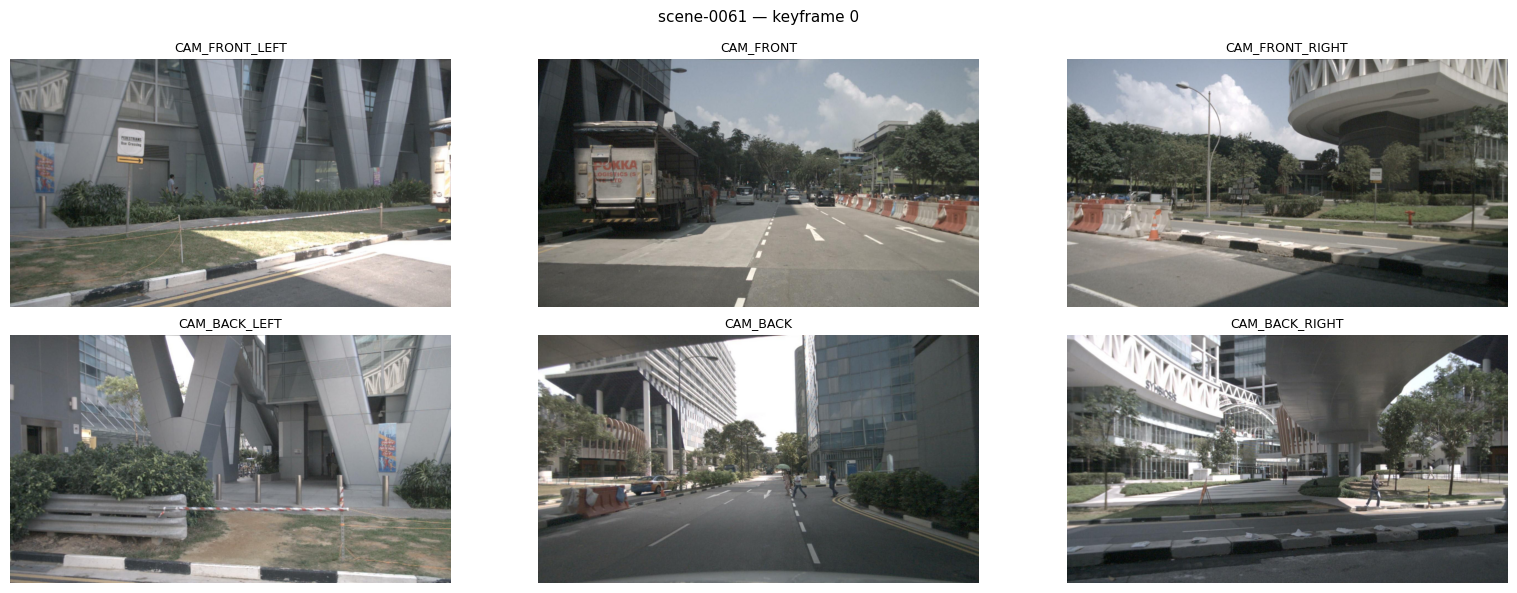

In [19]:
#@title 4 · The six cameras

import matplotlib.pyplot as plt
from PIL import Image

order = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT",
         "CAM_BACK_LEFT",  "CAM_BACK",  "CAM_BACK_RIGHT"]
fig, axes = plt.subplots(2, 3, figsize=(16, 6))
for ax, cam in zip(axes.ravel(), order):
    sd = nusc.get("sample_data", first["data"][cam])
    ax.imshow(Image.open(os.path.join(DATAROOT, sd["filename"])))
    ax.set_title(cam, fontsize=9)
    ax.axis("off")
plt.suptitle(f"{scene['name']} — keyframe 0", fontsize=11)
plt.tight_layout()
plt.show()

In [20]:
#@title 5 · CAN bus — action and state

import numpy as np
from nuscenes.can_bus.can_bus_api import NuScenesCanBus

can = NuScenesCanBus(dataroot=DATAROOT)
blacklist = set(f"scene-{n:04d}" for n in getattr(can, "can_blacklist", []))
print(f"scenes with unusable CAN data: {sorted(blacklist) or 'none'}\n")

assert scene["name"] not in blacklist, "pick a different scene"

for msg in ["vehicle_monitor", "steeranglefeedback", "pose", "ms_imu"]:
    try:
        rows = can.get_messages(scene["name"], msg)
    except Exception as e:
        print(f"{msg:<22} unavailable ({type(e).__name__})")
        continue
    ts = np.array([r["utime"] for r in rows], dtype=np.int64)
    hz = len(rows) / ((ts[-1] - ts[0]) / 1e6)
    print(f"{msg:<22} {len(rows):>6} msgs   {hz:>6.1f} Hz")
    print(f"    {', '.join(sorted(rows[0].keys()))}\n")

scenes with unusable CAN data: ['scene-0161', 'scene-0162', 'scene-0163', 'scene-0164', 'scene-0165', 'scene-0166', 'scene-0167', 'scene-0168', 'scene-0170', 'scene-0171', 'scene-0172', 'scene-0173', 'scene-0174', 'scene-0175', 'scene-0176', 'scene-0309', 'scene-0310', 'scene-0311', 'scene-0312', 'scene-0313', 'scene-0314']

vehicle_monitor            38 msgs      2.0 Hz
    available_distance, battery_level, brake, brake_switch, gear_position, left_signal, rear_left_rpm, rear_right_rpm, right_signal, steering, steering_speed, throttle, utime, vehicle_speed, yaw_rate

steeranglefeedback       1797 msgs     93.9 Hz
    utime, value

pose                      938 msgs     49.0 Hz
    accel, orientation, pos, rotation_rate, utime, vel

ms_imu                   1899 msgs     99.2 Hz
    linear_accel, q, rotation_rate, utime



vehicle_monitor        median  429.7 ms   p95  481.0 ms   max  929.8 ms
steeranglefeedback     median    7.4 ms   p95   25.7 ms   max   35.8 ms
pose                   median    7.8 ms   p95   20.2 ms   max   28.1 ms


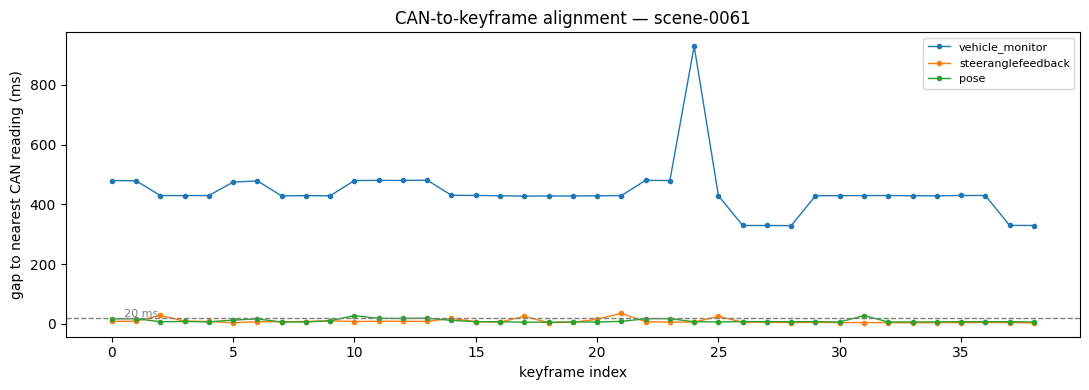


Under ~20 ms: nearest-neighbour is defensible.
Above it: interpolate, or resample onto a fixed grid.
Record whichever you pick — it changes what the model learns.


In [21]:
#@title 6 · Alignment — the decision to settle now

key_ts, tok = [], scene["first_sample_token"]
while tok:
    s = nusc.get("sample", tok)
    key_ts.append(s["timestamp"])
    tok = s["next"]
key_ts = np.array(key_ts, dtype=np.int64)

fig, ax = plt.subplots(figsize=(11, 4))
for msg in ["vehicle_monitor", "steeranglefeedback", "pose"]:
    try:
        rows = can.get_messages(scene["name"], msg)
    except Exception:
        continue
    can_ts = np.array([r["utime"] for r in rows], dtype=np.int64)
    idx = np.searchsorted(can_ts, key_ts).clip(0, len(can_ts) - 1)
    gap = np.abs(can_ts[idx] - key_ts) / 1e3
    print(f"{msg:<22} median {np.median(gap):6.1f} ms   "
          f"p95 {np.percentile(gap, 95):6.1f} ms   max {gap.max():6.1f} ms")
    ax.plot(gap, marker="o", ms=3, lw=1, label=msg)

ax.axhline(20, ls="--", lw=1, color="grey")
ax.text(0.5, 22, "20 ms", fontsize=8, color="grey")
ax.set_xlabel("keyframe index")
ax.set_ylabel("gap to nearest CAN reading (ms)")
ax.set_title(f"CAN-to-keyframe alignment — {scene['name']}")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("\nUnder ~20 ms: nearest-neighbour is defensible.")
print("Above it: interpolate, or resample onto a fixed grid.")
print("Record whichever you pick — it changes what the model learns.")

In [22]:
#@title 7 · Build the per-keyframe (action, state) table

import pandas as pd

vm = pd.DataFrame(can.get_messages(scene["name"], "vehicle_monitor")).sort_values("utime")
print("vehicle_monitor columns:\n ", list(vm.columns), "\n")

joined = pd.merge_asof(
    pd.DataFrame({"utime": key_ts}).sort_values("utime"),
    vm, on="utime", direction="nearest",
)
display(joined.head(12))
print(f"shape: {joined.shape}  — one row per keyframe, ready to condition on.")

# The columns that matter for an action-conditioned world model.
ACTION = [c for c in ["steering", "throttle", "brake"] if c in joined.columns]
STATE  = [c for c in ["vehicle_speed", "yaw_rate"]      if c in joined.columns]
print(f"\naction columns found: {ACTION}")
print(f"state  columns found: {STATE}")

vehicle_monitor columns:
  ['available_distance', 'battery_level', 'brake', 'brake_switch', 'gear_position', 'left_signal', 'rear_left_rpm', 'rear_right_rpm', 'right_signal', 'steering', 'steering_speed', 'throttle', 'utime', 'vehicle_speed', 'yaw_rate'] 



,utime,available_distance,battery_level,brake,brake_switch,gear_position,left_signal,rear_left_rpm,rear_right_rpm,right_signal,steering,steering_speed,throttle,vehicle_speed,yaw_rate
0,1532402927647951,120,91,0,1,7,0,275.2617,276.1791,0,3.0,1.811884e-13,0,31.44,0.6
1,1532402928147847,120,91,0,1,7,0,275.2617,276.1791,0,3.0,1.811884e-13,0,31.44,0.6
2,1532402928698048,120,91,0,1,7,1,267.7557,267.7557,0,3.5,1.811884e-13,0,30.73,0.6
3,1532402929197353,120,91,0,2,7,1,257.2473,256.5384,0,3.6,1.811884e-13,0,29.45,0.5
4,1532402929697797,120,91,0,1,7,0,244.4037,246.7389,0,3.6,1.811884e-13,0,28.09,0.2
5,1532402930152601,120,91,0,1,7,0,235.9803,237.3981,0,3.5,-2.000000e+00,0,27.07,0.4
6,1532402930648325,120,91,0,1,7,1,230.3925,229.2249,0,3.6,-2.000000e+00,0,26.25,0.6
7,1532402931198511,120,91,0,1,7,0,220.3428,221.0517,0,4.0,1.900000e+00,0,25.35,0.4
8,1532402931697833,120,91,0,1,7,0,215.8809,214.4631,0,4.7,1.811884e-13,0,24.51,0.6
9,1532402932197715,120,91,0,1,7,1,205.6227,206.7903,0,6.5,1.811884e-13,0,23.58,0.6


shape: (39, 15)  — one row per keyframe, ready to condition on.

action columns found: ['steering', 'throttle', 'brake']
state  columns found: ['vehicle_speed', 'yaw_rate']


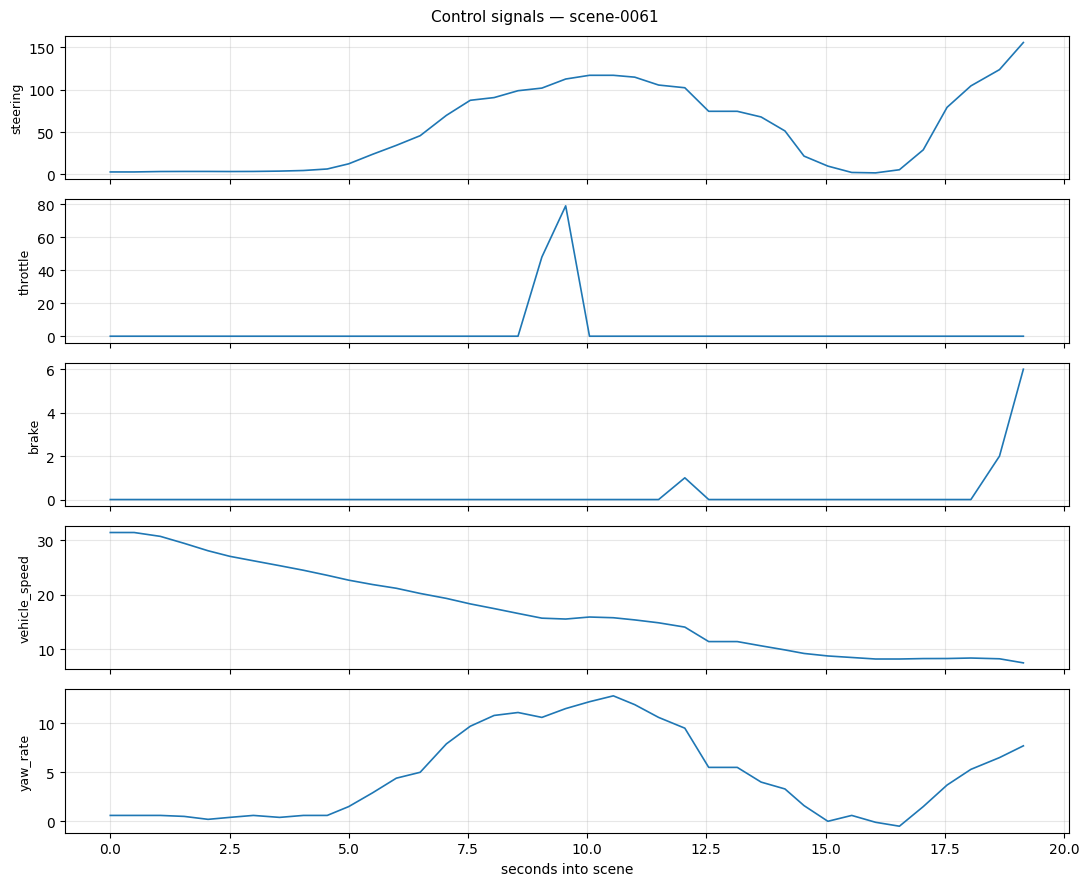

In [23]:
#@title 8 · Sanity-plot the control signals over one scene

cols = ACTION + STATE
if cols:
    t = (joined["utime"] - joined["utime"].iloc[0]) / 1e6
    fig, axes = plt.subplots(len(cols), 1, figsize=(11, 1.8 * len(cols)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, c in zip(axes, cols):
        ax.plot(t, joined[c], lw=1.2)
        ax.set_ylabel(c, fontsize=9)
        ax.grid(alpha=0.3)
    axes[-1].set_xlabel("seconds into scene")
    plt.suptitle(f"Control signals — {scene['name']}", fontsize=11)
    plt.tight_layout(); plt.show()
else:
    print("No expected columns found — check the printout in cell 7 and adjust.")

In [24]:
from nuscenes.can_bus.can_bus_api import NuScenesCanBus

can = NuScenesCanBus(dataroot=DATAROOT)

for scene in nusc.scene:
    name = scene["name"]

    try:
        vm = can.get_messages(name, "vehicle_monitor")
        sa = can.get_messages(name, "steeranglefeedback")

        print(
            f"{name}: "
            f"vehicle_monitor={len(vm)}, "
            f"steeranglefeedback={len(sa)}"
        )

    except Exception as e:
        print(f"{name}: ERROR - {e}")

scene-0061: vehicle_monitor=38, steeranglefeedback=1797
scene-0103: vehicle_monitor=40, steeranglefeedback=1896
scene-0553: vehicle_monitor=40, steeranglefeedback=1957
scene-0655: vehicle_monitor=40, steeranglefeedback=1947
scene-0757: vehicle_monitor=39, steeranglefeedback=1971
scene-0796: vehicle_monitor=40, steeranglefeedback=1943
scene-0916: vehicle_monitor=41, steeranglefeedback=1979
scene-1077: vehicle_monitor=41, steeranglefeedback=1960
scene-1094: vehicle_monitor=40, steeranglefeedback=1925
scene-1100: vehicle_monitor=40, steeranglefeedback=1923


In [25]:
import numpy as np
from PIL import Image
import os

CAMS = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT"]
H, W = 72, 128

scene = nusc.scene[0]
samples = []
token = scene["first_sample_token"]

while token:
    sample = nusc.get("sample", token)
    samples.append(sample)
    token = sample["next"]

frames = np.zeros((len(samples), 9, H, W), dtype=np.uint8)
timestamps = np.zeros(len(samples), dtype=np.int64)

for i, sample in enumerate(samples):
    timestamps[i] = sample["timestamp"]

    for j, camera in enumerate(CAMS):
        sd = nusc.get("sample_data", sample["data"][camera])
        image_path = os.path.join(DATAROOT, sd["filename"])

        with Image.open(image_path) as img:
            img = img.convert("RGB").resize((W, H), Image.Resampling.BILINEAR)
            frames[i, j*3:(j+1)*3] = np.asarray(img).transpose(2, 0, 1)

print("Scene:", scene["name"])
print("Frames shape:", frames.shape)
print("Data type:", frames.dtype)
print("Timestamps shape:", timestamps.shape)

Scene: scene-0061
Frames shape: (39, 9, 72, 128)
Data type: uint8
Timestamps shape: (39,)


In [26]:
import pandas as pd
import numpy as np

scene_name = scene["name"]

vm = pd.DataFrame(can.get_messages(scene_name, "vehicle_monitor"))
sa = pd.DataFrame(can.get_messages(scene_name, "steeranglefeedback"))

# Keep the original CAN timestamps to measure alignment gaps.
vm = vm[["utime", "throttle", "brake"]].sort_values("utime")
sa = sa[["utime", "value"]].rename(
    columns={"value": "steer"}
).sort_values("utime")

vm = vm.rename(columns={"utime": "vm_time"})
sa = sa.rename(columns={"utime": "steer_time"})

keys = pd.DataFrame({"timestamp": timestamps}).sort_values("timestamp")

# Match each camera keyframe to the nearest CAN reading.
aligned = pd.merge_asof(
    keys, vm,
    left_on="timestamp",
    right_on="vm_time",
    direction="nearest"
)

aligned = pd.merge_asof(
    aligned, sa,
    left_on="timestamp",
    right_on="steer_time",
    direction="nearest"
)

# nuScenes timestamps are in microseconds.
aligned["gap_vm_ms"] = (
    (aligned["timestamp"] - aligned["vm_time"]).abs() / 1000
)

aligned["gap_steer_ms"] = (
    (aligned["timestamp"] - aligned["steer_time"]).abs() / 1000
)

print("Scene:", scene_name)
print("Aligned rows:", len(aligned))

print(aligned[
    ["throttle", "brake", "steer", "gap_vm_ms", "gap_steer_ms"]
].head())

print("\nVehicle monitor median gap:",
      round(aligned["gap_vm_ms"].median(), 1), "ms")

print("Vehicle monitor p95 gap:",
      round(aligned["gap_vm_ms"].quantile(0.95), 1), "ms")

print("Rows with vehicle monitor gap >250 ms:",
      int((aligned["gap_vm_ms"] > 250).sum()))

Scene: scene-0061
Aligned rows: 39
   throttle  brake     steer  gap_vm_ms  gap_steer_ms
0         0      0  0.047124    479.849         8.585
1         0      0  0.054105     20.047         0.440
2         0      0  0.062832     70.889         0.978
3         0      0  0.061087     69.543         0.483
4         0      0  0.062832     70.740         1.276

Vehicle monitor median gap: 70.6 ms
Vehicle monitor p95 gap: 196.7 ms
Rows with vehicle monitor gap >250 ms: 2


In [27]:
print("Vehicle monitor gaps:")
print(aligned["gap_vm_ms"].describe())

print("\nSteering gaps:")
print(aligned["gap_steer_ms"].describe())

print("\nRows with vehicle monitor gaps >250 ms:")
print(
    aligned.loc[
        aligned["gap_vm_ms"] > 250,
        ["timestamp", "vm_time", "gap_vm_ms", "throttle", "brake"]
    ].to_string(index=False)
)

Vehicle monitor gaps:
count     39.000000
mean      91.492923
std       96.189345
min       18.953000
25%       69.281000
50%       70.561000
75%       71.300500
max      479.849000
Name: gap_vm_ms, dtype: float64

Steering gaps:
count    39.000000
mean      3.701897
std       2.495640
min       0.440000
25%       1.759500
50%       4.020000
75%       4.659000
max      13.673000
Name: gap_steer_ms, dtype: float64

Rows with vehicle monitor gaps >250 ms:
       timestamp          vm_time  gap_vm_ms  throttle  brake
1532402927647951 1532402928127800    479.849         0      0
1532402940197958 1532402940627263    429.305         0      0


In [28]:
print("Camera timestamp range:")
print(timestamps.min(), timestamps.max())

print("\nVehicle monitor timestamp range:")
print(vm["vm_time"].min(), vm["vm_time"].max())

print("\nSteering timestamp range:")
print(sa["steer_time"].min(), sa["steer_time"].max())

print("\nVehicle monitor interval statistics (ms):")
print((vm["vm_time"].diff().dropna() / 1000).describe())

Camera timestamp range:
1532402927647951 1532402946797517

Vehicle monitor timestamp range:
1532402928127800 1532402947127060

Steering timestamp range:
1532402927656536 1532402946801204

Vehicle monitor interval statistics (ms):
count     37.000000
mean     513.493514
std       82.202073
min      498.895000
25%      499.723000
50%      499.967000
75%      500.528000
max      999.987000
Name: vm_time, dtype: float64



### Timestamp Range and CAN Bus Frequency Check

I checked the timestamp ranges of the camera frames, vehicle monitor, and steering measurements for `scene-0061` to understand their time coverage.

**Observations:**
- Camera timestamps range from `1532402927647951` to `1532402946797517`.
- Vehicle monitor timestamps range from `1532402928127800` to `1532402947127060`.
- Steering timestamps range from `1532402927656536` to `1532402946801204`.
- Vehicle monitor messages are usually recorded about **500 ms apart**, which is approximately **2 Hz**.
- The maximum interval between vehicle monitor messages is approximately **1,000 ms**.

The vehicle monitor starts slightly after the first camera frame, which explains the larger timestamp gap for that frame. The longer interval between two vehicle monitor messages may also contribute to alignment gaps.

Overall, the timestamp ranges overlap for most of the scene. We will keep the alignment gaps in the processed dataset so that frames with larger differences can be identified during validation.


In [29]:
# Flag camera frames based on CAN bus timestamp gaps.
# 250 ms is a provisional threshold for checking alignment quality.

MAX_GAP_MS = 250

aligned["vm_valid"] = aligned["gap_vm_ms"] <= MAX_GAP_MS
aligned["steer_valid"] = aligned["gap_steer_ms"] <= MAX_GAP_MS

# A frame passes this check only if both CAN matches
# are within the selected threshold.
aligned["action_valid"] = (
    aligned["vm_valid"] & aligned["steer_valid"]
)

print("Scene:", scene_name)
print("Total keyframes:", len(aligned))
print("Frames passing alignment check:", aligned["action_valid"].sum())
print("Frames flagged for review:", (~aligned["action_valid"]).sum())

print("\nAlignment quality:")
print(
    aligned[
        ["gap_vm_ms", "gap_steer_ms", "action_valid"]
    ].describe(include="all")
)

Scene: scene-0061
Total keyframes: 39
Frames passing alignment check: 37
Frames flagged for review: 2

Alignment quality:
         gap_vm_ms  gap_steer_ms action_valid
count    39.000000     39.000000           39
unique         NaN           NaN            2
top            NaN           NaN         True
freq           NaN           NaN           37
mean     91.492923      3.701897          NaN
std      96.189345      2.495640          NaN
min      18.953000      0.440000          NaN
25%      69.281000      1.759500          NaN
50%      70.561000      4.020000          NaN
75%      71.300500      4.659000          NaN
max     479.849000     13.673000          NaN


In [30]:
# Extract the three front-facing cameras for every Mini scene.

scene_data = {}

for current_scene in nusc.scene:
    scene_samples = []
    token = current_scene["first_sample_token"]

    while token:
        sample = nusc.get("sample", token)
        scene_samples.append(sample)
        token = sample["next"]

    scene_frames = np.zeros(
        (len(scene_samples), 9, H, W),
        dtype=np.uint8
    )

    scene_times = np.zeros(
        len(scene_samples),
        dtype=np.int64
    )

    for i, sample in enumerate(scene_samples):
        scene_times[i] = sample["timestamp"]

        for j, camera in enumerate(CAMS):
            sd = nusc.get(
                "sample_data",
                sample["data"][camera]
            )

            image_path = os.path.join(
                DATAROOT,
                sd["filename"]
            )

            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img = img.resize(
                    (W, H),
                    Image.Resampling.BILINEAR
                )

                scene_frames[i, j*3:(j+1)*3] = (
                    np.asarray(img).transpose(2, 0, 1)
                )

    scene_data[current_scene["name"]] = {
        "frames": scene_frames,
        "timestamps": scene_times
    }

    print(
        current_scene["name"],
        "| frames:",
        scene_frames.shape
    )

print("\nTotal scenes:", len(scene_data))
print(
    "Total keyframes:",
    sum(len(s["timestamps"]) for s in scene_data.values())
)

scene-0061 | frames: (39, 9, 72, 128)
scene-0103 | frames: (40, 9, 72, 128)
scene-0553 | frames: (41, 9, 72, 128)
scene-0655 | frames: (41, 9, 72, 128)
scene-0757 | frames: (41, 9, 72, 128)
scene-0796 | frames: (40, 9, 72, 128)
scene-0916 | frames: (41, 9, 72, 128)
scene-1077 | frames: (41, 9, 72, 128)
scene-1094 | frames: (40, 9, 72, 128)
scene-1100 | frames: (40, 9, 72, 128)

Total scenes: 10
Total keyframes: 404



### Extracting Camera Frames from All 10 Scenes

After checking the extraction process on one scene, I used the same approach for all 10 scenes in nuScenes Mini.

For each keyframe, I extracted images from the front-left, front, and front-right cameras. I resized them to 128 × 72 pixels and combined the RGB images into a 9-channel array.

The extraction completed for all 10 scenes, giving **404 keyframes** in total. Each scene's frames and timestamps are stored separately in `scene_data`.


In [31]:
# Align throttle, brake, and steering for all 10 scenes.

aligned_data = {}

for name, data in scene_data.items():

    vm = pd.DataFrame(
        can.get_messages(name, "vehicle_monitor")
    )[["utime", "throttle", "brake"]].sort_values("utime")

    sa = pd.DataFrame(
        can.get_messages(name, "steeranglefeedback")
    )[["utime", "value"]].sort_values("utime")

    vm = vm.rename(columns={"utime": "vm_time"})
    sa = sa.rename(columns={
        "utime": "steer_time",
        "value": "steer"
    })

    keys = pd.DataFrame({
        "timestamp": data["timestamps"]
    }).sort_values("timestamp")

    matched = pd.merge_asof(
        keys, vm,
        left_on="timestamp",
        right_on="vm_time",
        direction="nearest"
    )

    matched = pd.merge_asof(
        matched, sa,
        left_on="timestamp",
        right_on="steer_time",
        direction="nearest"
    )

    matched["gap_vm_ms"] = (
        (matched["timestamp"] - matched["vm_time"]).abs() / 1000
    )

    matched["gap_steer_ms"] = (
        (matched["timestamp"] - matched["steer_time"]).abs() / 1000
    )

    matched["action_valid"] = (
        (matched["gap_vm_ms"] <= 250) &
        (matched["gap_steer_ms"] <= 250)
    )

    aligned_data[name] = matched

    print(
        f"{name}: "
        f"{len(matched)} frames | "
        f"{matched['action_valid'].sum()} passed | "
        f"{(~matched['action_valid']).sum()} flagged"
    )

print("\nTotal aligned frames:",
      sum(len(df) for df in aligned_data.values()))

print("Total flagged frames:",
      sum((~df["action_valid"]).sum()
          for df in aligned_data.values()))

scene-0061: 39 frames | 37 passed | 2 flagged
scene-0103: 40 frames | 39 passed | 1 flagged
scene-0553: 41 frames | 40 passed | 1 flagged
scene-0655: 41 frames | 40 passed | 1 flagged
scene-0757: 41 frames | 39 passed | 2 flagged
scene-0796: 40 frames | 40 passed | 0 flagged
scene-0916: 41 frames | 41 passed | 0 flagged
scene-1077: 41 frames | 41 passed | 0 flagged
scene-1094: 40 frames | 40 passed | 0 flagged
scene-1100: 40 frames | 40 passed | 0 flagged

Total aligned frames: 404
Total flagged frames: 7



### Aligning Driving Actions with Camera Frames

Next, I matched the camera frames with throttle, brake, and steering measurements for all 10 scenes.

I used `vehicle_monitor` for throttle and brake, and `steeranglefeedback` for steering. Since these measurements have different timestamps, I used nearest-neighbor matching to find the closest CAN bus reading for each camera frame.

I also calculated the timestamp gaps and flagged frames where either gap was greater than 250 ms.

Out of **404 frames, 397 passed the initial alignment check and 7 were flagged**. I kept all the frames for further review.


In [32]:
# Summarize timestamp alignment quality across all scenes.

summary = []

for name, df in aligned_data.items():
    summary.append({
        "scene": name,
        "frames": len(df),
        "vm_median_ms": round(df["gap_vm_ms"].median(), 1),
        "vm_p95_ms": round(df["gap_vm_ms"].quantile(0.95), 1),
        "vm_max_ms": round(df["gap_vm_ms"].max(), 1),
        "steer_median_ms": round(df["gap_steer_ms"].median(), 1),
        "steer_max_ms": round(df["gap_steer_ms"].max(), 1),
        "flagged": int((~df["action_valid"]).sum())
    })

summary_df = pd.DataFrame(summary)

print(summary_df.to_string(index=False))

print("\nOverall vehicle monitor median gap:",
      round(pd.concat(
          [df["gap_vm_ms"] for df in aligned_data.values()]
      ).median(), 1), "ms")

print("Overall steering median gap:",
      round(pd.concat(
          [df["gap_steer_ms"] for df in aligned_data.values()]
      ).median(), 1), "ms")

     scene  frames  vm_median_ms  vm_p95_ms  vm_max_ms  steer_median_ms  steer_max_ms  flagged
scene-0061      39          70.6      196.7      479.8              4.0          13.7        2
scene-0103      40          49.0      149.6      351.5              3.5           8.6        1
scene-0553      41         179.9      231.4      270.5              1.4           4.7        1
scene-0655      41         242.6      247.4      252.5              2.1          10.2        1
scene-0757      41         173.4      224.1      327.8              3.2          12.6        2
scene-0796      40          83.9       84.8      184.4              3.7           7.5        0
scene-0916      41         177.2      178.3      178.7              1.6           7.2        0
scene-1077      41         176.0      225.8      225.9              2.8           5.4        0
scene-1094      40         170.3      218.3      219.0              2.0           4.2        0
scene-1100      40         168.9      219.6      2


### Checking Alignment Quality Across Scenes

I calculated the median, 95th percentile, and maximum timestamp gaps for each scene to see how well the CAN bus measurements aligned with the camera frames.

The overall median gap was **171.0 ms for throttle and brake** and **2.4 ms for steering**.

Steering measurements were generally closer to the camera timestamps. I also noticed that `scene-0655` had a vehicle monitor median gap of 242.6 ms, which was close to the 250 ms threshold.

This check helped identify differences between scenes and confirmed why the actual timestamp gaps should be kept in the processed data.


In [33]:
import os
import numpy as np

OUTPUT_DIR = "/content/drive/MyDrive/DriveJEPA/nuscenes_processed"
os.makedirs(OUTPUT_DIR, exist_ok=True)

for name, data in scene_data.items():
    df = aligned_data[name]

    # Three driving actions in a fixed order:
    # throttle, brake, steering
    actions = df[
        ["throttle", "brake", "steer"]
    ].to_numpy(dtype=np.float32)

    output_path = os.path.join(OUTPUT_DIR, f"{name}.npz")

    np.savez_compressed(
        output_path,
        frames=data["frames"],
        timestamps=data["timestamps"],
        actions=actions,
        gap_vm_ms=df["gap_vm_ms"].to_numpy(dtype=np.float32),
        gap_steer_ms=df["gap_steer_ms"].to_numpy(dtype=np.float32),
        action_valid=df["action_valid"].to_numpy(dtype=bool)
    )

    print(
        f"Saved {name}: "
        f"{len(data['frames'])} frames | "
        f"{actions.shape[0]} actions"
    )

print("\nSaved files:", len([
    f for f in os.listdir(OUTPUT_DIR)
    if f.endswith(".npz")
]))
print("Output folder:", OUTPUT_DIR)

Saved scene-0061: 39 frames | 39 actions
Saved scene-0103: 40 frames | 40 actions
Saved scene-0553: 41 frames | 41 actions
Saved scene-0655: 41 frames | 41 actions
Saved scene-0757: 41 frames | 41 actions
Saved scene-0796: 40 frames | 40 actions
Saved scene-0916: 41 frames | 41 actions
Saved scene-1077: 41 frames | 41 actions
Saved scene-1094: 40 frames | 40 actions
Saved scene-1100: 40 frames | 40 actions

Saved files: 10
Output folder: /content/drive/MyDrive/DriveJEPA/nuscenes_processed


In [34]:
# Verify all saved scene files before using them for training.

import os
import numpy as np

total_frames = 0
total_flagged = 0

for name in scene_data:
    path = os.path.join(OUTPUT_DIR, f"{name}.npz")

    with np.load(path) as data:
        frames = data["frames"]
        actions = data["actions"]
        timestamps = data["timestamps"]
        valid = data["action_valid"]

        n = len(frames)

        assert frames.shape == (n, 9, 72, 128)
        assert frames.dtype == np.uint8
        assert actions.shape == (n, 3)
        assert len(timestamps) == n
        assert len(valid) == n
        assert len(data["gap_vm_ms"]) == n
        assert len(data["gap_steer_ms"]) == n
        assert np.isfinite(actions).all()

        flagged = int((~valid).sum())
        total_frames += n
        total_flagged += flagged

        print(f"{name}: VERIFIED | {n} frames | {flagged} flagged")

print("\nTotal verified frames:", total_frames)
print("Total flagged frames:", total_flagged)

assert total_frames == 404
assert total_flagged == 7

print("\nAll saved files passed verification!")

scene-0061: VERIFIED | 39 frames | 2 flagged
scene-0103: VERIFIED | 40 frames | 1 flagged
scene-0553: VERIFIED | 41 frames | 1 flagged
scene-0655: VERIFIED | 41 frames | 1 flagged
scene-0757: VERIFIED | 41 frames | 2 flagged
scene-0796: VERIFIED | 40 frames | 0 flagged
scene-0916: VERIFIED | 41 frames | 0 flagged
scene-1077: VERIFIED | 41 frames | 0 flagged
scene-1094: VERIFIED | 40 frames | 0 flagged
scene-1100: VERIFIED | 40 frames | 0 flagged

Total verified frames: 404
Total flagged frames: 7

All saved files passed verification!


In [35]:
import json
import numpy as np
import os

# Create a reproducible scene-level split.
scene_names = sorted(scene_data.keys())

rng = np.random.default_rng(42)
shuffled_scenes = rng.permutation(scene_names).tolist()

train_scenes = sorted(shuffled_scenes[:7])
val_scenes = sorted(shuffled_scenes[7:])

split = {
    "train": train_scenes,
    "val": val_scenes
}

# Save the split alongside the processed scene files.
split_path = os.path.join(OUTPUT_DIR, "scene_split.json")

with open(split_path, "w") as f:
    json.dump(split, f, indent=2)

print("Training scenes:", train_scenes)
print("Validation scenes:", val_scenes)

print("\nTraining frames:",
      sum(len(scene_data[s]["timestamps"]) for s in train_scenes))

print("Validation frames:",
      sum(len(scene_data[s]["timestamps"]) for s in val_scenes))

print("\nSplit saved to:", split_path)

assert len(train_scenes) == 7
assert len(val_scenes) == 3
assert set(train_scenes).isdisjoint(val_scenes)
assert set(train_scenes + val_scenes) == set(scene_names)

print("Scene-level split verified!")

Training scenes: ['scene-0061', 'scene-0553', 'scene-0655', 'scene-0757', 'scene-0796', 'scene-0916', 'scene-1077']
Validation scenes: ['scene-0103', 'scene-1094', 'scene-1100']

Training frames: 284
Validation frames: 120

Split saved to: /content/drive/MyDrive/DriveJEPA/nuscenes_processed/scene_split.json
Scene-level split verified!


In [36]:
import os
import json

OUTPUT_DIR = "/content/drive/MyDrive/DriveJEPA/nuscenes_processed"
split_path = os.path.join(OUTPUT_DIR, "scene_split.json")

# Read the existing split.
with open(split_path, "r") as f:
    old_split = json.load(f)

# Convert the existing train/val lists into a scene-level mapping.
if "train" in old_split and "val" in old_split:
    train_scenes = old_split["train"]
    val_scenes = old_split["val"]

    assert len(train_scenes) == 7
    assert len(val_scenes) == 3
    assert set(train_scenes).isdisjoint(val_scenes)

    new_split = {
        scene: {"split": "train"}
        for scene in train_scenes
    }

    new_split.update({
        scene: {"split": "val"}
        for scene in val_scenes
    })

else:
    # The manifest has already been converted.
    new_split = old_split

assert len(new_split) == 10
assert sum(v["split"] == "train" for v in new_split.values()) == 7
assert sum(v["split"] == "val" for v in new_split.values()) == 3

# Save the corrected manifest.
with open(split_path, "w") as f:
    json.dump(new_split, f, indent=4)

print("Manifest updated successfully!")
print("Training scenes: 7")
print("Validation scenes: 3")
print("Saved to:", split_path)

Manifest updated successfully!
Training scenes: 7
Validation scenes: 3
Saved to: /content/drive/MyDrive/DriveJEPA/nuscenes_processed/scene_split.json



### Training and Validation Split

The 10 processed nuScenes Mini scenes were divided into 7 training scenes and 3 validation scenes using a fixed random seed of 42.

The split was performed at the scene level to prevent frames from the same driving sequence from appearing in both datasets.

- Training: 7 scenes, 284 keyframes
- Validation: 3 scenes, 120 keyframes
- Total: 404 keyframes

The split was verified to ensure that no scenes overlap between training and validation. The scene names were saved in `scene_split.json` for reproducibility.

All frames were retained, including those flagged during timestamp alignment. The corresponding quality flags remain available in the processed `.npz` files.


In [37]:
import os
import json
import numpy as np

OUTPUT_DIR = "/content/drive/MyDrive/DriveJEPA/nuscenes_processed"

# Load the saved scene-level split manifest.
with open(os.path.join(OUTPUT_DIR, "scene_split.json"), "r") as f:
    split = json.load(f)

# Separate scenes into training and validation groups.
train_scenes = [
    scene for scene, info in split.items()
    if info["split"] == "train"
]

val_scenes = [
    scene for scene, info in split.items()
    if info["split"] == "val"
]

scene_groups = {
    "train": train_scenes,
    "val": val_scenes
}

# Verify the scene-level split.
assert len(split) == 10
assert len(train_scenes) == 7
assert len(val_scenes) == 3
assert set(train_scenes).isdisjoint(set(val_scenes))
assert set(info["split"] for info in split.values()) == {"train", "val"}

total_frames = 0
total_flagged = 0

# Check every saved scene file.
for group in ["train", "val"]:

    group_frames = 0
    group_flagged = 0

    print(f"\n{group.upper()} DATASET")

    for scene_name in scene_groups[group]:

        file_path = os.path.join(
            OUTPUT_DIR, f"{scene_name}.npz"
        )

        assert os.path.isfile(file_path), (
            f"Missing file: {scene_name}"
        )

        with np.load(file_path) as data:

            n = len(data["frames"])

            # Verify saved frame and action dimensions.
            assert data["frames"].shape == (n, 9, 72, 128)
            assert data["actions"].shape == (n, 3)
            assert len(data["timestamps"]) == n
            assert len(data["action_valid"]) == n

            # Check that action values are finite.
            assert np.isfinite(data["actions"]).all()

            # Count frames with alignment gaps above the threshold.
            flagged = int(
                (~data["action_valid"]).sum()
            )

            group_frames += n
            group_flagged += flagged

            print(
                f"{scene_name}: {n} frames | "
                f"{flagged} flagged"
            )

    total_frames += group_frames
    total_flagged += group_flagged

    print(f"{group} total: {group_frames} frames")
    print(f"{group} flagged: {group_flagged}")

# Final dataset checks.
assert total_frames == 404
assert total_flagged == 7

print("\nTotal frames:", total_frames)
print("Total flagged:", total_flagged)
print("Final dataset handoff check: PASSED")


TRAIN DATASET
scene-0061: 39 frames | 2 flagged
scene-0553: 41 frames | 1 flagged
scene-0655: 41 frames | 1 flagged
scene-0757: 41 frames | 2 flagged
scene-0796: 40 frames | 0 flagged
scene-0916: 41 frames | 0 flagged
scene-1077: 41 frames | 0 flagged
train total: 284 frames
train flagged: 6

VAL DATASET
scene-0103: 40 frames | 1 flagged
scene-1094: 40 frames | 0 flagged
scene-1100: 40 frames | 0 flagged
val total: 120 frames
val flagged: 1

Total frames: 404
Total flagged: 7
Final dataset handoff check: PASSED


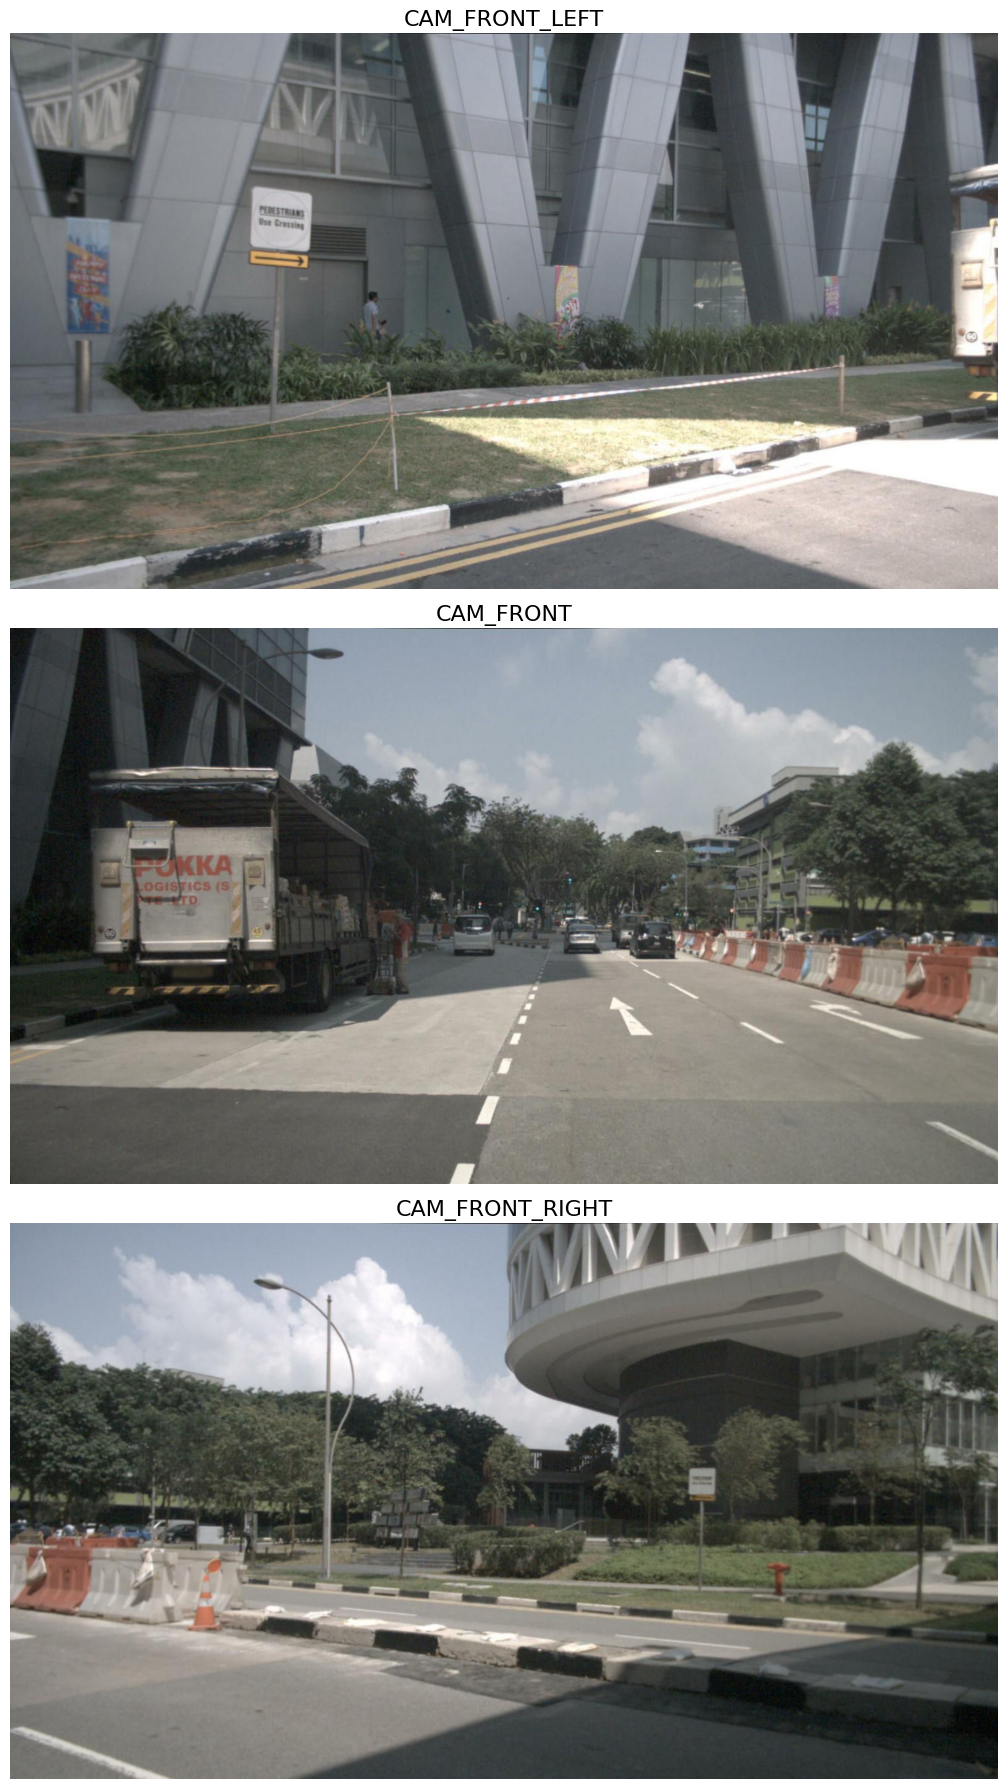

In [38]:
import matplotlib.pyplot as plt
from PIL import Image
import os

scene = nusc.scene[0]
sample = nusc.get("sample", scene["first_sample_token"])

cameras = [
    "CAM_FRONT_LEFT",
    "CAM_FRONT",
    "CAM_FRONT_RIGHT"
]

fig, axes = plt.subplots(3, 1, figsize=(18, 18))

for ax, camera in zip(axes, cameras):
    sd = nusc.get("sample_data", sample["data"][camera])
    image_path = os.path.join(DATAROOT, sd["filename"])

    with Image.open(image_path) as img:
        ax.imshow(img.copy())

    ax.set_title(camera, fontsize=16)
    ax.axis("off")

plt.tight_layout()
plt.show()

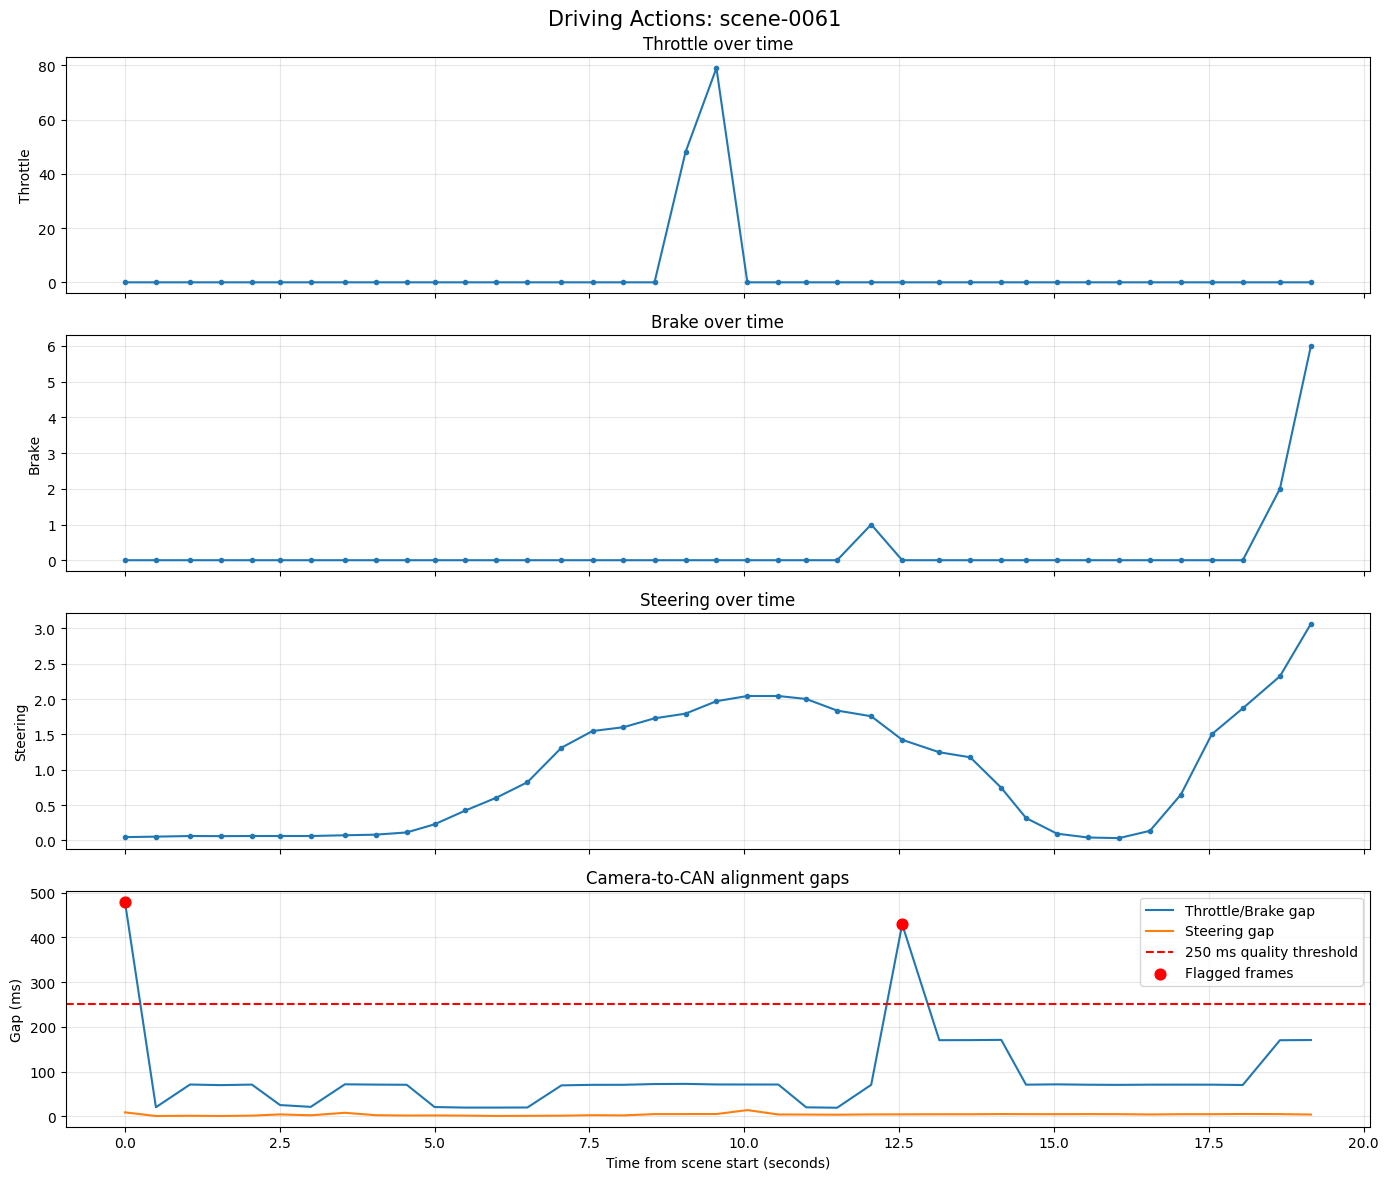

Total keyframes: 39
Flagged frames: 2
Action order: [throttle, brake, steer]


In [39]:
import numpy as np
import matplotlib.pyplot as plt
import os

scene_name = "scene-0061"
file_path = os.path.join(OUTPUT_DIR, f"{scene_name}.npz")

with np.load(file_path) as data:
    timestamps = data["timestamps"]
    actions = data["actions"]
    gap_vm_ms = data["gap_vm_ms"]
    gap_steer_ms = data["gap_steer_ms"]
    action_valid = data["action_valid"]

# Time in seconds from the first camera keyframe.
time_s = (timestamps - timestamps[0]) / 1e6

fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)

signals = [
    ("Throttle", actions[:, 0]),
    ("Brake", actions[:, 1]),
    ("Steering", actions[:, 2])
]

for ax, (name, values) in zip(axes[:3], signals):
    ax.plot(time_s, values, marker="o", markersize=3)
    ax.set_ylabel(name)
    ax.set_title(f"{name} over time")
    ax.grid(alpha=0.3)

# Visualize camera-to-CAN timestamp differences.
axes[3].plot(time_s, gap_vm_ms, label="Throttle/Brake gap")
axes[3].plot(time_s, gap_steer_ms, label="Steering gap")
axes[3].axhline(
    250, color="red", linestyle="--",
    label="250 ms quality threshold"
)

# Highlight frames flagged by the alignment check.
flagged = ~action_valid

axes[3].scatter(
    time_s[flagged],
    gap_vm_ms[flagged],
    color="red",
    s=60,
    zorder=5,
    label="Flagged frames"
)

axes[3].set_ylabel("Gap (ms)")
axes[3].set_xlabel("Time from scene start (seconds)")
axes[3].set_title("Camera-to-CAN alignment gaps")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.suptitle(f"Driving Actions: {scene_name}", fontsize=15)
plt.tight_layout()
plt.show()

print("Total keyframes:", len(actions))
print("Flagged frames:", flagged.sum())
print("Action order: [throttle, brake, steer]")

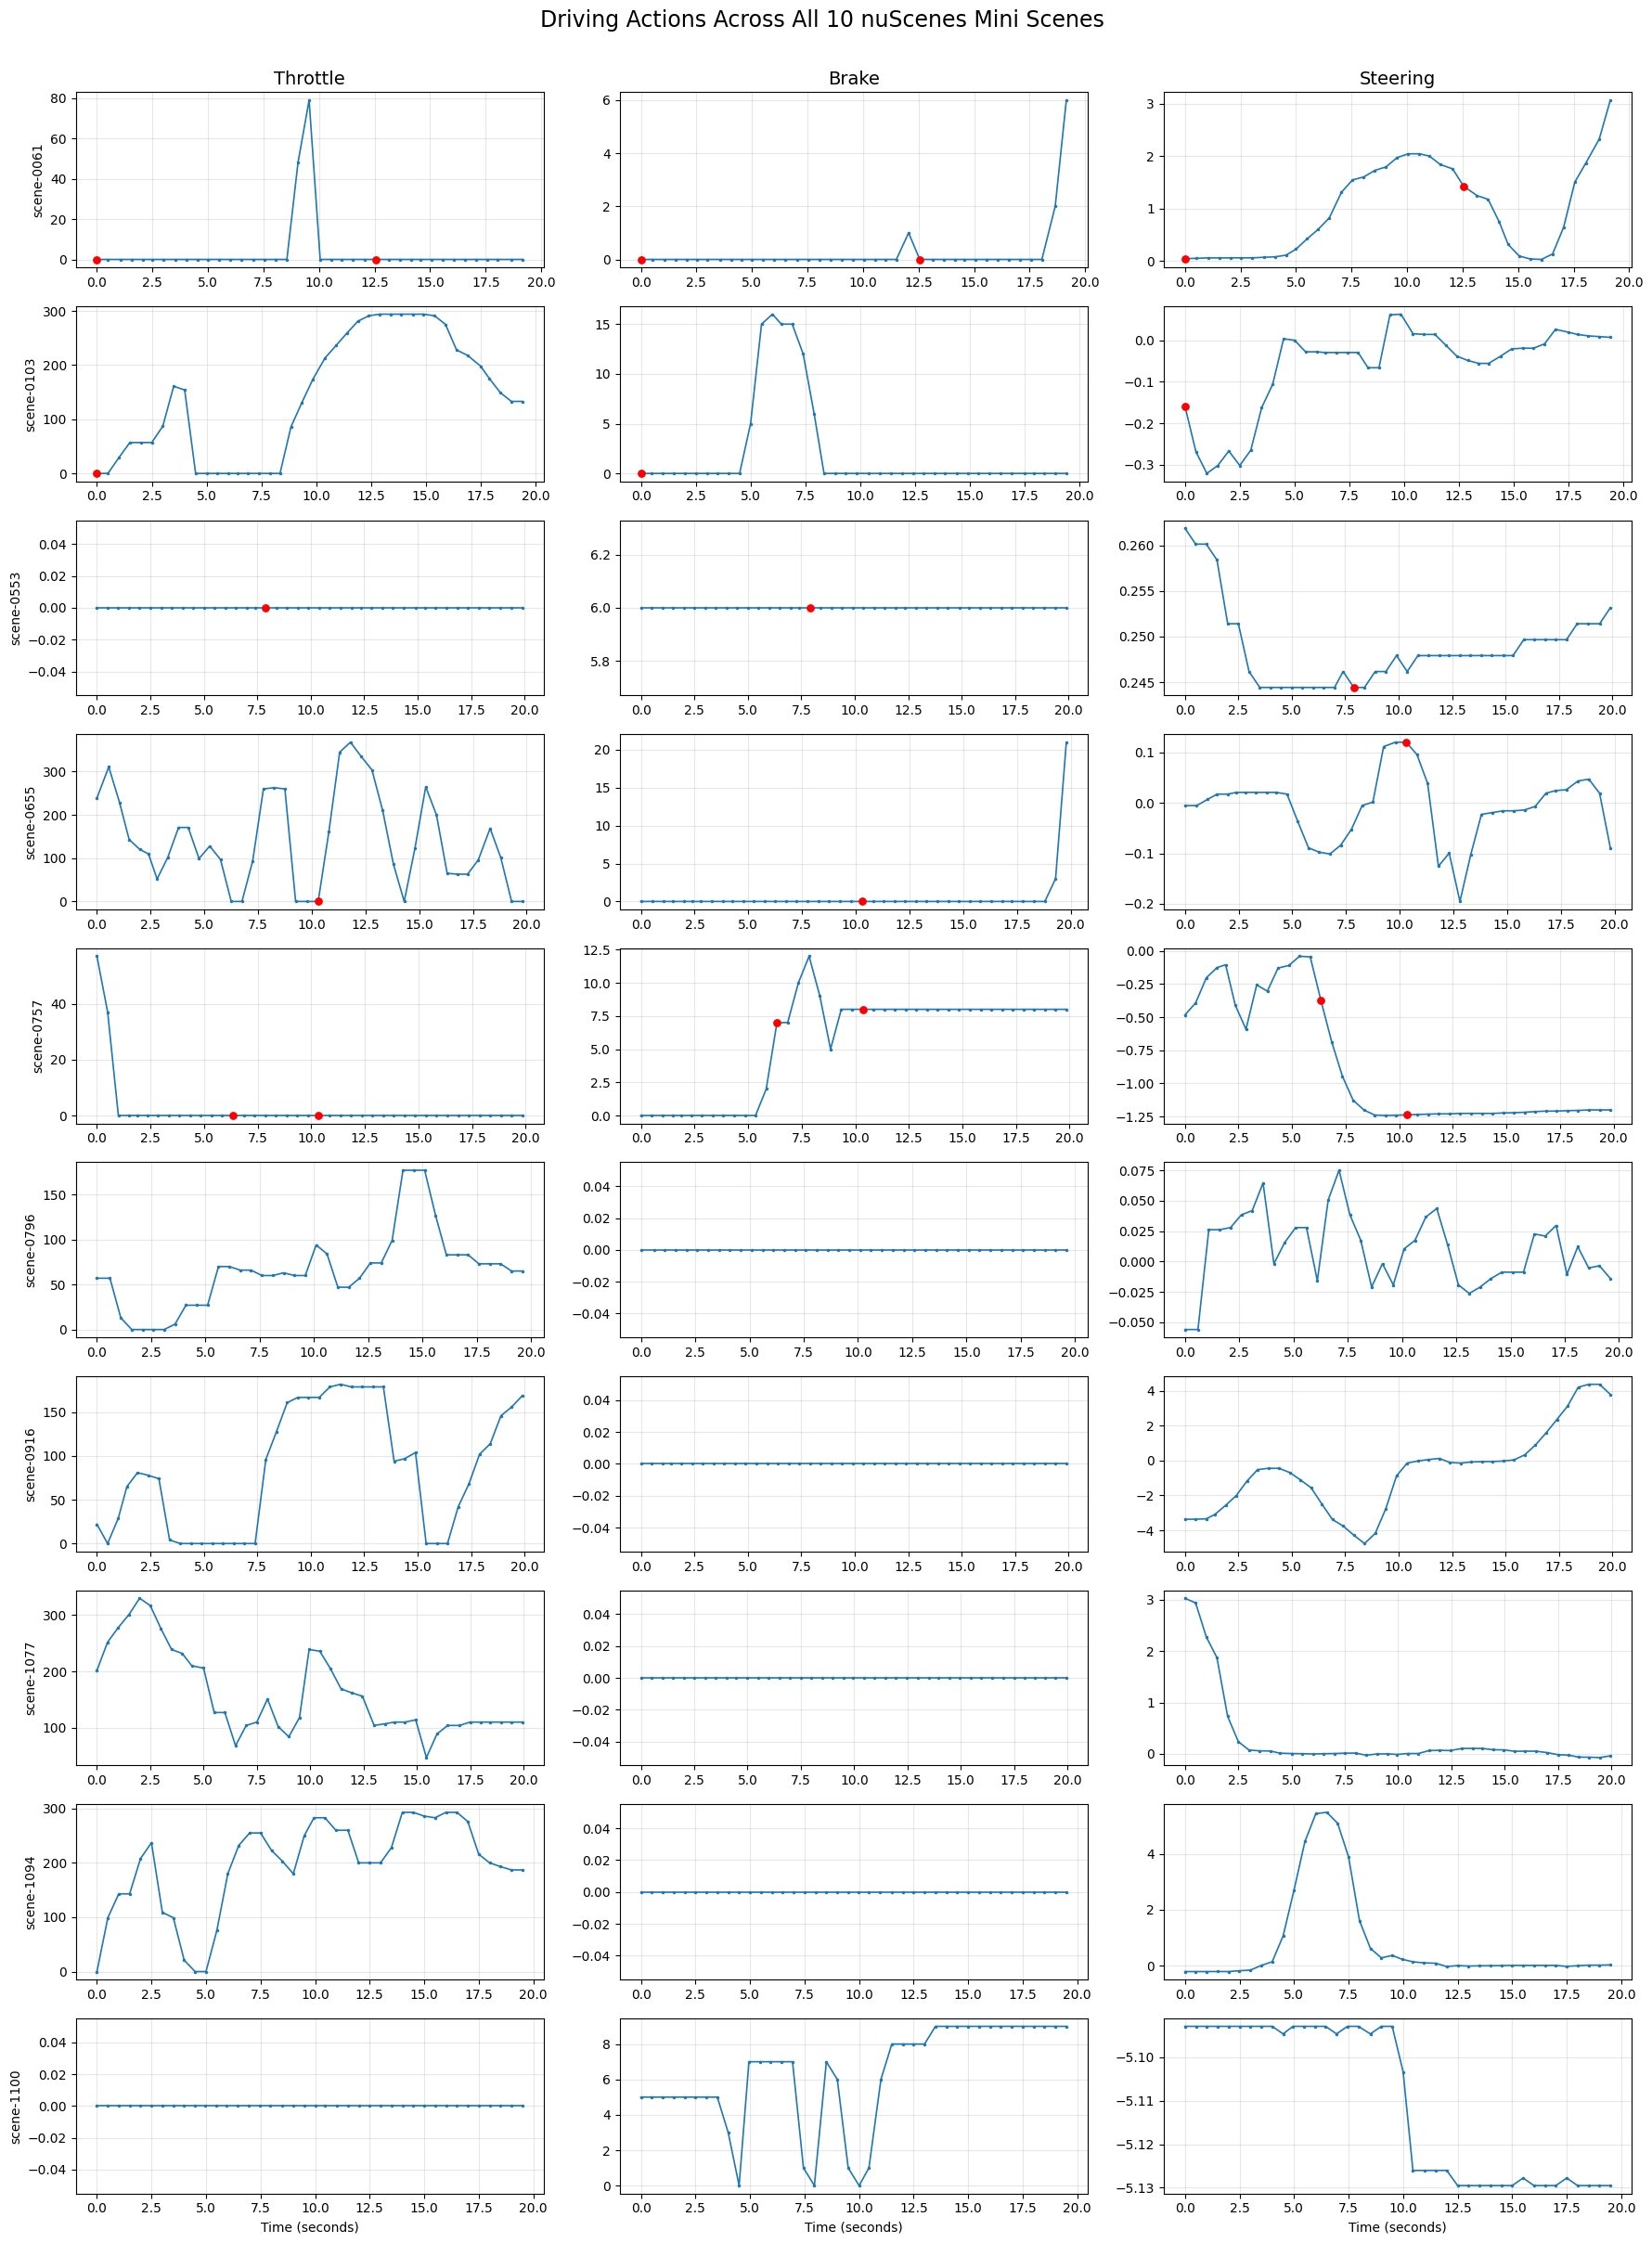

Scenes checked: 10
Total keyframes: 404
Flagged keyframes: 7
Red markers indicate flagged timestamp alignments.


In [40]:
import os
import numpy as np
import matplotlib.pyplot as plt

scene_names = sorted([
    f.replace(".npz", "")
    for f in os.listdir(OUTPUT_DIR)
    if f.endswith(".npz")
])

assert len(scene_names) == 10, "Expected 10 processed scenes"

fig, axes = plt.subplots(
    len(scene_names), 3,
    figsize=(18, 24),
    squeeze=False
)

action_names = ["Throttle", "Brake", "Steering"]

total_frames = 0
total_flagged = 0

for row, scene_name in enumerate(scene_names):

    file_path = os.path.join(OUTPUT_DIR, f"{scene_name}.npz")

    with np.load(file_path) as data:
        actions = data["actions"]
        timestamps = data["timestamps"]
        valid = data["action_valid"]

    time_s = (timestamps - timestamps[0]) / 1e6
    flagged = ~valid

    total_frames += len(actions)
    total_flagged += int(flagged.sum())

    for col in range(3):
        ax = axes[row, col]

        ax.plot(
            time_s,
            actions[:, col],
            marker=".",
            markersize=3,
            linewidth=1.2
        )

        # Mark frames with large timestamp alignment gaps.
        if flagged.any():
            ax.scatter(
                time_s[flagged],
                actions[flagged, col],
                color="red",
                s=28,
                zorder=3
            )

        if row == 0:
            ax.set_title(action_names[col], fontsize=14)

        if col == 0:
            ax.set_ylabel(scene_name, fontsize=10)

        if row == len(scene_names) - 1:
            ax.set_xlabel("Time (seconds)")

        ax.grid(alpha=0.3)

plt.suptitle(
    "Driving Actions Across All 10 nuScenes Mini Scenes",
    fontsize=17,
    y=1.005
)

plt.tight_layout()
plt.show()

print("Scenes checked:", len(scene_names))
print("Total keyframes:", total_frames)
print("Flagged keyframes:", total_flagged)
print("Red markers indicate flagged timestamp alignments.")

assert total_frames == 404
assert total_flagged == 7

In [41]:
import os
import numpy as np
import pandas as pd

scene_names = sorted(
    f[:-4] for f in os.listdir(OUTPUT_DIR)
    if f.endswith(".npz")
)

def get_nearest_indices(source_times, target_times):
    pos = np.searchsorted(source_times, target_times)

    left = np.clip(pos - 1, 0, len(source_times) - 1)
    right = np.clip(pos, 0, len(source_times) - 1)

    choose_right = (
        np.abs(source_times[right] - target_times)
        < np.abs(source_times[left] - target_times)
    )

    return np.where(choose_right, right, left)


total_checked = 0
all_passed = True

for name in scene_names:

    with np.load(os.path.join(OUTPUT_DIR, f"{name}.npz")) as saved:
        timestamps = saved["timestamps"]
        actions = saved["actions"]
        vm_gaps = saved["gap_vm_ms"]
        steer_gaps = saved["gap_steer_ms"]

    vm = pd.DataFrame(
        can.get_messages(name, "vehicle_monitor")
    ).sort_values("utime")

    sa = pd.DataFrame(
        can.get_messages(name, "steeranglefeedback")
    ).sort_values("utime")

    vm_times = vm["utime"].to_numpy(dtype=np.int64)
    sa_times = sa["utime"].to_numpy(dtype=np.int64)

    vm_idx = get_nearest_indices(vm_times, timestamps)
    sa_idx = get_nearest_indices(sa_times, timestamps)

    expected_actions = np.column_stack([
        vm["throttle"].to_numpy()[vm_idx],
        vm["brake"].to_numpy()[vm_idx],
        sa["value"].to_numpy()[sa_idx]
    ]).astype(np.float32)

    expected_vm_gap = (
        np.abs(timestamps - vm_times[vm_idx]) / 1000
    )

    expected_steer_gap = (
        np.abs(timestamps - sa_times[sa_idx]) / 1000
    )

    action_check = np.allclose(
        actions, expected_actions, atol=1e-5, rtol=1e-5
    )

    gap_check = (
        np.allclose(vm_gaps, expected_vm_gap, atol=1e-3)
        and np.allclose(steer_gaps, expected_steer_gap, atol=1e-3)
    )

    passed = action_check and gap_check
    all_passed = all_passed and passed

    total_checked += len(timestamps)

    print(
        f"{name}: {'PASS' if passed else 'CHECK'} | "
        f"Actions: {action_check} | Gaps: {gap_check}"
    )

print("\nTotal scenes:", len(scene_names))
print("Total keyframes checked:", total_checked)
print("Final verification:", "PASSED" if all_passed else "NEEDS REVIEW")

scene-0061: PASS | Actions: True | Gaps: True
scene-0103: PASS | Actions: True | Gaps: True
scene-0553: PASS | Actions: True | Gaps: True
scene-0655: PASS | Actions: True | Gaps: True
scene-0757: PASS | Actions: True | Gaps: True
scene-0796: PASS | Actions: True | Gaps: True
scene-0916: PASS | Actions: True | Gaps: True
scene-1077: PASS | Actions: True | Gaps: True
scene-1094: PASS | Actions: True | Gaps: True
scene-1100: PASS | Actions: True | Gaps: True

Total scenes: 10
Total keyframes checked: 404
Final verification: PASSED



## 12 Hz Camera Sweep Data — Initial Inspection

The initial preprocessing used 2 Hz camera keyframes, resulting in 404 frames across 10 nuScenes Mini scenes.

To increase the available training data, the intermediate camera sweep frames are now being examined.

The same three forward-facing cameras are retained:
- CAM_FRONT_LEFT
- CAM_FRONT
- CAM_FRONT_RIGHT

The target resolution remains 72 × 128, with all three RGB images stacked into a 9-channel representation.

This inspection checks the available camera sweep samples, their timestamps, and the number of non-keyframe images before extraction.


In [42]:
import pandas as pd
import numpy as np

sweep_results = []

for scene in nusc.scene:

    scene_name = scene["name"]
    first_sample = nusc.get(
        "sample", scene["first_sample_token"]
    )

    for cam in CAMS:

        # Start from the first keyframe for this camera
        sd = nusc.get(
            "sample_data", first_sample["data"][cam]
        )

        # Move backwards to the first available sample_data
        while sd["prev"]:
            sd = nusc.get("sample_data", sd["prev"])

        records = []

        # Traverse the complete camera sample_data sequence
        while sd:
            records.append(sd)
            if not sd["next"]:
                break
            sd = nusc.get("sample_data", sd["next"])

        timestamps = np.array(
            [r["timestamp"] for r in records],
            dtype=np.int64
        )

        intervals_ms = np.diff(timestamps) / 1000

        sweep_results.append({
            "scene": scene_name,
            "camera": cam,
            "total_frames": len(records),
            "keyframes": sum(r["is_key_frame"] for r in records),
            "sweep_frames": sum(not r["is_key_frame"] for r in records),
            "median_interval_ms": (
                np.median(intervals_ms)
                if len(intervals_ms) else np.nan
            )
        })

sweep_df = pd.DataFrame(sweep_results)

display(sweep_df)

print("\nTotal camera records:", sweep_df["total_frames"].sum())
print("Total keyframes:", sweep_df["keyframes"].sum())
print("Total intermediate frames:", sweep_df["sweep_frames"].sum())

,scene,camera,total_frames,keyframes,sweep_frames,median_interval_ms
0,scene-0061,CAM_FRONT_LEFT,224,39,185,100.0
1,scene-0061,CAM_FRONT,224,39,185,100.0
2,scene-0061,CAM_FRONT_RIGHT,217,39,178,100.0
3,scene-0103,CAM_FRONT_LEFT,231,40,191,100.0
4,scene-0103,CAM_FRONT,229,40,189,100.0
5,scene-0103,CAM_FRONT_RIGHT,233,40,193,100.0
6,scene-0553,CAM_FRONT_LEFT,239,41,198,100.0
7,scene-0553,CAM_FRONT,237,41,196,100.0
8,scene-0553,CAM_FRONT_RIGHT,239,41,198,100.0
9,scene-0655,CAM_FRONT_LEFT,237,41,196,100.0



Total camera records: 7024
Total keyframes: 1212
Total intermediate frames: 5812



### Camera Sweep Frequency Analysis

The initial inspection identified 5,812 intermediate camera frames across the 10 nuScenes Mini scenes.

The median timestamp interval is approximately 100 ms across all three selected cameras. This corresponds to an observed sampling frequency of approximately 10 Hz.

Before extracting the additional frames, the timestamp intervals are examined in more detail to understand the available camera sampling rate and identify any irregular intervals.


In [43]:
# Examine the observed sampling frequency for each camera

frequency_df = sweep_df.copy()

frequency_df["observed_frequency_hz"] = (
    1000 / frequency_df["median_interval_ms"]
)

display(
    frequency_df[
        [
            "scene",
            "camera",
            "median_interval_ms",
            "observed_frequency_hz",
            "sweep_frames"
        ]
    ].round(2)
)

print(
    "\nOverall median frequency:",
    round(
        1000 / frequency_df["median_interval_ms"].median(),
        2
    ),
    "Hz"
)

,scene,camera,median_interval_ms,observed_frequency_hz,sweep_frames
0,scene-0061,CAM_FRONT_LEFT,100.0,10.0,185
1,scene-0061,CAM_FRONT,100.0,10.0,185
2,scene-0061,CAM_FRONT_RIGHT,100.0,10.0,178
3,scene-0103,CAM_FRONT_LEFT,100.0,10.0,191
4,scene-0103,CAM_FRONT,100.0,10.0,189
5,scene-0103,CAM_FRONT_RIGHT,100.0,10.0,193
6,scene-0553,CAM_FRONT_LEFT,100.0,10.0,198
7,scene-0553,CAM_FRONT,100.0,10.0,196
8,scene-0553,CAM_FRONT_RIGHT,100.0,10.0,198
9,scene-0655,CAM_FRONT_LEFT,100.0,10.0,196



Overall median frequency: 10.0 Hz


### Camera Sweep Timestamp Verification

Before extracting the additional camera sweep frames, I checked
the timestamp intervals for the three forward-facing cameras
across all 10 nuScenes Mini scenes.

This helps determine the actual camera sampling frequency
and whether the available frames support the 12 Hz target.

In [44]:
import numpy as np
import pandas as pd

cameras = [
    "CAM_FRONT_LEFT",
    "CAM_FRONT",
    "CAM_FRONT_RIGHT"
]

results = []

for camera in cameras:

    intervals_ms = []
    frame_count = 0

    for scene in nusc.scene:

        # Collect keyframe and sweep timestamps for this scene.
        scene_samples = []
        token = scene["first_sample_token"]

        while token:
            sample = nusc.get("sample", token)
            scene_samples.append(sample)
            token = sample["next"]

        timestamps = []

        for sample in scene_samples:

            sd = nusc.get(
                "sample_data",
                sample["data"][camera]
            )

            # Follow the camera sample_data chain backward.
            while sd:
                timestamps.append(sd["timestamp"])

                if not sd["prev"]:
                    break

                sd = nusc.get("sample_data", sd["prev"])

        # Remove repeated records from overlapping chains.
        timestamps = np.array(
            sorted(set(timestamps)),
            dtype=np.int64
        )

        frame_count += len(timestamps)

        if len(timestamps) > 1:
            gaps = np.diff(timestamps) / 1000
            intervals_ms.extend(gaps.tolist())

    intervals_ms = np.array(intervals_ms)

    median_gap = np.median(intervals_ms)
    frequency = 1000 / median_gap

    results.append({
        "Camera": camera,
        "Frames": frame_count,
        "Median interval (ms)": round(median_gap, 2),
        "Estimated frequency (Hz)": round(frequency, 2),
        "Min interval (ms)": round(np.min(intervals_ms), 2),
        "Max interval (ms)": round(np.max(intervals_ms), 2)
    })

frequency_df = pd.DataFrame(results)

print("CAMERA SWEEP FREQUENCY CHECK")
print(frequency_df.to_string(index=False))

print("\nTarget frequency: 12 Hz")
print("Target interval: 83.33 ms")

CAMERA SWEEP FREQUENCY CHECK
         Camera  Frames  Median interval (ms)  Estimated frequency (Hz)  Min interval (ms)  Max interval (ms)
 CAM_FRONT_LEFT    2344                 100.0                      10.0              46.35             200.00
      CAM_FRONT    2342                 100.0                      10.0              48.68             200.00
CAM_FRONT_RIGHT    2338                 100.0                      10.0              49.23             200.77

Target frequency: 12 Hz
Target interval: 83.33 ms


### Camera Sweep Synchronization Check

The camera sweep timestamps showed a median frequency of 10 Hz.
I checked how closely the front-left and front-right camera frames
align with the front camera before combining them for training.

In [45]:
import numpy as np
import pandas as pd

CAMS = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT"]

sync_results = []

for scene in nusc.scene:
    scene_name = scene["name"]
    camera_times = {}

    first_sample = nusc.get("sample", scene["first_sample_token"])
    last_sample = nusc.get("sample", scene["last_sample_token"])

    for cam in CAMS:
        first_sd = nusc.get(
            "sample_data", first_sample["data"][cam]
        )
        last_sd = nusc.get(
            "sample_data", last_sample["data"][cam]
        )

        # Start at the earliest available sweep for this scene.
        sd = first_sd
        while sd["prev"]:
            previous = nusc.get("sample_data", sd["prev"])

            if previous["timestamp"] < first_sample["timestamp"] - 500000:
                break

            sd = previous

        timestamps = []

        # Follow the camera frames in chronological order.
        while True:
            timestamps.append(sd["timestamp"])

            if sd["token"] == last_sd["token"]:
                break

            if not sd["next"]:
                break

            sd = nusc.get("sample_data", sd["next"])

        camera_times[cam] = np.array(
            sorted(set(timestamps)), dtype=np.int64
        )

    front_times = camera_times["CAM_FRONT"]

    for cam in ["CAM_FRONT_LEFT", "CAM_FRONT_RIGHT"]:
        other_times = camera_times[cam]

        positions = np.searchsorted(other_times, front_times)
        right = np.clip(positions, 0, len(other_times) - 1)
        left = np.clip(positions - 1, 0, len(other_times) - 1)

        differences = np.minimum(
            np.abs(other_times[right] - front_times),
            np.abs(other_times[left] - front_times)
        ) / 1000.0

        sync_results.append({
            "Scene": scene_name,
            "Camera": cam,
            "Front frames": len(front_times),
            "Median gap (ms)": round(float(np.median(differences)), 2),
            "Max gap (ms)": round(float(np.max(differences)), 2),
            "Within 50 ms (%)": round(
                float(np.mean(differences <= 50) * 100), 2
            )
        })

sync_df = pd.DataFrame(sync_results)

print("CAMERA SYNCHRONIZATION CHECK")
print(sync_df.to_string(index=False))

print("\nOVERALL SUMMARY")
print(
    sync_df.groupby("Camera")[
        ["Median gap (ms)", "Max gap (ms)", "Within 50 ms (%)"]
    ].mean().round(2)
)

CAMERA SYNCHRONIZATION CHECK
     Scene          Camera  Front frames  Median gap (ms)  Max gap (ms)  Within 50 ms (%)
scene-0061  CAM_FRONT_LEFT           224             7.62         92.38             98.21
scene-0061 CAM_FRONT_RIGHT           224             7.88         92.12             96.88
scene-0103  CAM_FRONT_LEFT           229             7.61         57.60             99.13
scene-0103 CAM_FRONT_RIGHT           229             8.08         91.92             99.56
scene-0553  CAM_FRONT_LEFT           237             7.61         57.60             99.58
scene-0553 CAM_FRONT_RIGHT           237             8.08         41.92            100.00
scene-0655  CAM_FRONT_LEFT           237             7.61         57.60             99.58
scene-0655 CAM_FRONT_RIGHT           237             8.08         58.52             99.16
scene-0757  CAM_FRONT_LEFT           237             7.61         92.39             99.58
scene-0757 CAM_FRONT_RIGHT           237             8.08         41.92

### Building Synchronized Camera Sweep Sequences

I used CAM_FRONT as the reference camera and matched the
nearest frames from CAM_FRONT_LEFT and CAM_FRONT_RIGHT.

Matches within 50 ms were considered synchronized.
Frames outside this threshold were flagged before extraction.

The original camera timestamps are preserved, and the
existing keyframe dataset is kept unchanged.

In [46]:
import numpy as np
import pandas as pd

CAMS = ["CAM_FRONT_LEFT", "CAM_FRONT", "CAM_FRONT_RIGHT"]
SYNC_THRESHOLD_US = 50_000

sweep_matches = {}
sweep_summary = []

def get_scene_camera_records(scene, camera):
    first_sample = nusc.get("sample", scene["first_sample_token"])
    last_sample = nusc.get("sample", scene["last_sample_token"])

    first_sd = nusc.get(
        "sample_data", first_sample["data"][camera]
    )
    last_sd = nusc.get(
        "sample_data", last_sample["data"][camera]
    )

    records = []
    sd = first_sd

    # Include sweeps immediately preceding the first keyframe.
    while sd["prev"]:
        previous = nusc.get("sample_data", sd["prev"])

        if previous["timestamp"] < first_sample["timestamp"] - 500_000:
            break

        sd = previous

    # Collect frames up to the last scene keyframe.
    while True:
        records.append({
            "timestamp": sd["timestamp"],
            "token": sd["token"],
            "filename": sd["filename"]
        })

        if sd["token"] == last_sd["token"] or not sd["next"]:
            break

        sd = nusc.get("sample_data", sd["next"])

    return sorted(records, key=lambda x: x["timestamp"])


def nearest_record(records, timestamp):
    times = np.array(
        [r["timestamp"] for r in records],
        dtype=np.int64
    )

    pos = np.searchsorted(times, timestamp)

    candidates = [
        i for i in [pos - 1, pos]
        if 0 <= i < len(records)
    ]

    best = min(
        candidates,
        key=lambda i: abs(int(times[i]) - int(timestamp))
    )

    gap_us = abs(int(times[best]) - int(timestamp))

    return records[best], gap_us


for scene in nusc.scene:
    name = scene["name"]

    camera_records = {
        cam: get_scene_camera_records(scene, cam)
        for cam in CAMS
    }

    matches = []

    for front in camera_records["CAM_FRONT"]:
        timestamp = front["timestamp"]

        left, left_gap = nearest_record(
            camera_records["CAM_FRONT_LEFT"], timestamp
        )

        right, right_gap = nearest_record(
            camera_records["CAM_FRONT_RIGHT"], timestamp
        )

        valid = (
            left_gap <= SYNC_THRESHOLD_US
            and right_gap <= SYNC_THRESHOLD_US
        )

        matches.append({
            "timestamp": timestamp,
            "front": front["filename"],
            "left": left["filename"],
            "right": right["filename"],
            "left_gap_ms": left_gap / 1000,
            "right_gap_ms": right_gap / 1000,
            "sync_valid": valid
        })

    sweep_matches[name] = matches

    valid_count = sum(m["sync_valid"] for m in matches)

    sweep_summary.append({
        "Scene": name,
        "Front frames": len(matches),
        "Valid triplets": valid_count,
        "Flagged": len(matches) - valid_count
    })

summary_df = pd.DataFrame(sweep_summary)

print("SYNCHRONIZED CAMERA SWEEP SUMMARY")
print(summary_df.to_string(index=False))

print("\nTOTAL")
print("Front reference frames:", summary_df["Front frames"].sum())
print("Valid triplets:", summary_df["Valid triplets"].sum())
print("Flagged triplets:", summary_df["Flagged"].sum())

SYNCHRONIZED CAMERA SWEEP SUMMARY
     Scene  Front frames  Valid triplets  Flagged
scene-0061           224             213       11
scene-0103           229             226        3
scene-0553           237             236        1
scene-0655           237             234        3
scene-0757           237             236        1
scene-0796           234             232        2
scene-0916           240             239        1
scene-1077           240             236        4
scene-1094           232             230        2
scene-1100           232             231        1

TOTAL
Front reference frames: 2342
Valid triplets: 2313
Flagged triplets: 29


In [47]:
import os
import numpy as np
from PIL import Image

# Use the first valid triplet from scene-0061.
test_match = next(
    m for m in sweep_matches["scene-0061"]
    if m["sync_valid"]
)

camera_order = ["left", "front", "right"]
images = []

for camera in camera_order:
    image_path = os.path.join(
        nusc.dataroot,
        test_match[camera]
    )

    assert os.path.isfile(image_path), (
        f"Missing image: {image_path}"
    )

    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img = img.resize((128, 72), Image.Resampling.BILINEAR)
        images.append(np.array(img, dtype=np.uint8))

# Combine three RGB images into nine channels.
stacked_frame = np.concatenate(images, axis=2)

assert stacked_frame.shape == (72, 128, 9)
assert stacked_frame.dtype == np.uint8

print("Scene: scene-0061")
print("Image shape:", stacked_frame.shape)
print("Data type:", stacked_frame.dtype)
print("Left camera gap:", test_match["left_gap_ms"], "ms")
print("Right camera gap:", test_match["right_gap_ms"], "ms")
print("Image extraction test: PASSED")

Scene: scene-0061
Image shape: (72, 128, 9)
Data type: uint8
Left camera gap: 7.616 ms
Right camera gap: 7.879 ms
Image extraction test: PASSED


### Full Camera Sweep Image Extraction

After testing one synchronized camera triplet, I extracted
the valid camera sweep frames from all 10 scenes.

Each frame combines the front-left, front, and front-right
camera images into a 9-channel array at 72 × 128 resolution.

Only camera triplets within the 50 ms synchronization
threshold are included.

In [48]:
import os
import numpy as np
from PIL import Image

SWEEP_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR, "camera_sweeps"
)

os.makedirs(SWEEP_OUTPUT_DIR, exist_ok=True)

total_extracted = 0

for scene_name, matches in sweep_matches.items():

    valid_matches = [
        m for m in matches if m["sync_valid"]
    ]

    frames = []
    timestamps = []

    for match in valid_matches:

        images = []

        for camera in ["left", "front", "right"]:

            image_path = os.path.join(
                nusc.dataroot, match[camera]
            )

            with Image.open(image_path) as img:
                img = img.convert("RGB")
                img = img.resize(
                    (128, 72),
                    Image.Resampling.BILINEAR
                )

                images.append(
                    np.array(img, dtype=np.uint8)
                )

        stacked = np.concatenate(images, axis=2)

        # Convert HWC to CHW for model input.
        stacked = np.transpose(stacked, (2, 0, 1))

        assert stacked.shape == (9, 72, 128)

        frames.append(stacked)
        timestamps.append(match["timestamp"])

    frames = np.stack(frames)
    timestamps = np.array(timestamps, dtype=np.int64)

    save_path = os.path.join(
        SWEEP_OUTPUT_DIR, f"{scene_name}_sweeps.npz"
    )

    np.savez_compressed(
        save_path,
        frames=frames,
        timestamps=timestamps
    )

    total_extracted += len(frames)

    print(
        f"{scene_name}: {len(frames)} frames saved"
    )

print("\nTotal extracted:", total_extracted)

assert total_extracted == 2313

print("Camera sweep image extraction: PASSED")

scene-0061: 213 frames saved
scene-0103: 226 frames saved
scene-0553: 236 frames saved
scene-0655: 234 frames saved
scene-0757: 236 frames saved
scene-0796: 232 frames saved
scene-0916: 239 frames saved
scene-1077: 236 frames saved
scene-1094: 230 frames saved
scene-1100: 231 frames saved

Total extracted: 2313
Camera sweep image extraction: PASSED


### CAN-bus Alignment for Camera Sweeps

I matched the extracted camera sweep timestamps with the
vehicle's throttle, brake, and steering measurements.

I used nearest-timestamp matching, following the same method
used for the original keyframe dataset.

Frames with CAN-bus alignment gaps greater than 250 ms
were flagged for review.

In [49]:
import os
import numpy as np
import pandas as pd

SWEEP_OUTPUT_DIR = os.path.join(OUTPUT_DIR, "camera_sweeps")
ALIGNED_SWEEP_DIR = os.path.join(OUTPUT_DIR, "camera_sweeps_aligned")

os.makedirs(ALIGNED_SWEEP_DIR, exist_ok=True)

total_frames = 0
total_flagged = 0

for scene in nusc.scene:

    name = scene["name"]

    input_path = os.path.join(
        SWEEP_OUTPUT_DIR, f"{name}_sweeps.npz"
    )

    assert os.path.isfile(input_path), f"Missing sweep file: {name}"

    # Load the saved camera frames and timestamps.
    with np.load(input_path) as data:
        frames = data["frames"]
        timestamps = data["timestamps"].astype(np.int64)

    # Read the same CAN-bus signals used for keyframes.
    vm = pd.DataFrame(
        can.get_messages(name, "vehicle_monitor")
    )[["utime", "throttle", "brake"]].sort_values("utime")

    sa = pd.DataFrame(
        can.get_messages(name, "steeranglefeedback")
    )[["utime", "value"]].sort_values("utime")

    vm = vm.rename(columns={"utime": "vm_time"})

    sa = sa.rename(columns={
        "utime": "steer_time",
        "value": "steer"
    })

    assert not vm.empty, f"No vehicle monitor data: {name}"
    assert not sa.empty, f"No steering data: {name}"

    # Match each sweep timestamp to the nearest CAN reading.
    keys = pd.DataFrame({
        "timestamp": timestamps
    }).sort_values("timestamp")

    matched = pd.merge_asof(
        keys,
        vm,
        left_on="timestamp",
        right_on="vm_time",
        direction="nearest"
    )

    matched = pd.merge_asof(
        matched,
        sa,
        left_on="timestamp",
        right_on="steer_time",
        direction="nearest"
    )

    # Calculate timestamp differences in milliseconds.
    matched["gap_vm_ms"] = (
        (matched["timestamp"] - matched["vm_time"]).abs() / 1000
    )

    matched["gap_steer_ms"] = (
        (matched["timestamp"] - matched["steer_time"]).abs() / 1000
    )

    matched["action_valid"] = (
        (matched["gap_vm_ms"] <= 250) &
        (matched["gap_steer_ms"] <= 250)
    )

    # Keep actions in the same order as the keyframe dataset.
    actions = matched[
        ["throttle", "brake", "steer"]
    ].to_numpy(dtype=np.float32)

    action_valid = matched["action_valid"].to_numpy(dtype=bool)

    assert frames.shape == (len(timestamps), 9, 72, 128)
    assert actions.shape == (len(timestamps), 3)
    assert np.isfinite(actions).all()
    assert np.array_equal(
        matched["timestamp"].to_numpy(dtype=np.int64),
        timestamps
    )

    # Save aligned sweeps separately from the original files.
    output_path = os.path.join(
        ALIGNED_SWEEP_DIR, f"{name}_sweeps.npz"
    )

    np.savez_compressed(
        output_path,
        frames=frames,
        timestamps=timestamps,
        actions=actions,
        gap_vm_ms=matched["gap_vm_ms"].to_numpy(dtype=np.float32),
        gap_steer_ms=matched["gap_steer_ms"].to_numpy(dtype=np.float32),
        action_valid=action_valid
    )

    flagged = int((~action_valid).sum())

    total_frames += len(timestamps)
    total_flagged += flagged

    print(
        f"{name}: {len(timestamps)} frames | "
        f"{flagged} action flagged"
    )

print("\nTotal aligned sweep frames:", total_frames)
print("Total action flagged:", total_flagged)

assert total_frames == 2313

print("CAN-bus sweep alignment: PASSED")
print("Saved to:", ALIGNED_SWEEP_DIR)

scene-0061: 213 frames | 9 action flagged
scene-0103: 226 frames | 2 action flagged
scene-0553: 236 frames | 6 action flagged
scene-0655: 234 frames | 6 action flagged
scene-0757: 236 frames | 12 action flagged
scene-0796: 232 frames | 0 action flagged
scene-0916: 239 frames | 0 action flagged
scene-1077: 236 frames | 0 action flagged
scene-1094: 230 frames | 0 action flagged
scene-1100: 231 frames | 0 action flagged

Total aligned sweep frames: 2313
Total action flagged: 35
CAN-bus sweep alignment: PASSED
Saved to: /content/drive/MyDrive/DriveJEPA/nuscenes_processed/camera_sweeps_aligned


In [50]:
import os
import json
import numpy as np

OUTPUT_DIR = "/content/drive/MyDrive/DriveJEPA/nuscenes_processed"

ALIGNED_SWEEP_DIR = os.path.join(
    OUTPUT_DIR, "camera_sweeps_aligned"
)

with open(os.path.join(OUTPUT_DIR, "scene_split.json"), "r") as f:
    split = json.load(f)

expected_counts = {
    "scene-0061": 213,
    "scene-0103": 226,
    "scene-0553": 236,
    "scene-0655": 234,
    "scene-0757": 236,
    "scene-0796": 232,
    "scene-0916": 239,
    "scene-1077": 236,
    "scene-1094": 230,
    "scene-1100": 231
}

assert len(split) == 10
assert set(split) == set(expected_counts)
assert sum(v["split"] == "train" for v in split.values()) == 7
assert sum(v["split"] == "val" for v in split.values()) == 3

total_frames = 0
total_flagged = 0

for group in ["train", "val"]:

    group_frames = 0
    group_flagged = 0

    print(f"\n{group.upper()} SWEEP DATASET")

    for scene_name, info in split.items():

        if info["split"] != group:
            continue

        file_path = os.path.join(
            ALIGNED_SWEEP_DIR,
            f"{scene_name}_sweeps.npz"
        )

        assert os.path.isfile(file_path), scene_name

        with np.load(file_path) as data:

            n = len(data["frames"])

            assert n == expected_counts[scene_name]
            assert data["frames"].shape == (n, 9, 72, 128)
            assert data["frames"].dtype == np.uint8
            assert data["actions"].shape == (n, 3)
            assert len(data["timestamps"]) == n
            assert len(data["action_valid"]) == n
            assert len(data["gap_vm_ms"]) == n
            assert len(data["gap_steer_ms"]) == n

            assert np.isfinite(data["actions"]).all()
            assert np.isfinite(data["gap_vm_ms"]).all()
            assert np.isfinite(data["gap_steer_ms"]).all()

            timestamps = data["timestamps"]
            assert np.all(np.diff(timestamps) > 0)

            expected_valid = (
                (data["gap_vm_ms"] <= 250) &
                (data["gap_steer_ms"] <= 250)
            )

            assert np.array_equal(
                data["action_valid"],
                expected_valid
            )

            flagged = int((~data["action_valid"]).sum())

            group_frames += n
            group_flagged += flagged

            print(
                f"{scene_name}: {n} frames | "
                f"{flagged} flagged"
            )

    total_frames += group_frames
    total_flagged += group_flagged

    print(f"{group} total: {group_frames}")
    print(f"{group} flagged: {group_flagged}")

assert total_frames == 2313
assert total_flagged == 35

print("\nTotal frames:", total_frames)
print("Total flagged:", total_flagged)
print("Usable frames:", total_frames - total_flagged)
print("FINAL SWEEP DATASET VERIFICATION: PASSED")


TRAIN SWEEP DATASET
scene-0061: 213 frames | 9 flagged
scene-0553: 236 frames | 6 flagged
scene-0655: 234 frames | 6 flagged
scene-0757: 236 frames | 12 flagged
scene-0796: 232 frames | 0 flagged
scene-0916: 239 frames | 0 flagged
scene-1077: 236 frames | 0 flagged
train total: 1626
train flagged: 33

VAL SWEEP DATASET
scene-0103: 226 frames | 2 flagged
scene-1094: 230 frames | 0 flagged
scene-1100: 231 frames | 0 flagged
val total: 687
val flagged: 2

Total frames: 2313
Total flagged: 35
Usable frames: 2278
FINAL SWEEP DATASET VERIFICATION: PASSED


## 13. Training Dataset and DataLoader

This section prepares the processed nuScenes camera sweep data for JEPA training.

Each sample consists of:
- **Context:** One current frame containing three synchronized camera views (nine channels).
- **Future target:** A frame five time steps ahead, corresponding to a 0.5-second prediction horizon at 10 Hz.
- **Driving actions:** Throttle, brake, and steering values corresponding to the current frame.

The original scene-level training and validation split is preserved to prevent data leakage between the two sets. Samples with invalid action measurements at the current frame are excluded.

PyTorch DataLoaders are created for both training and validation.

In [69]:
# Create PyTorch Dataset

import os
import json
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

OUTPUT_DIR = "/content/drive/MyDrive/DriveJEPA/nuscenes_processed"
ALIGNED_SWEEP_DIR = os.path.join(OUTPUT_DIR, "camera_sweeps_aligned")

PREDICTION_HORIZON = 5
BATCH_SIZE = 16

with open(os.path.join(OUTPUT_DIR, "scene_split.json"), "r") as f:
    split = json.load(f)


class NuScenesSweepDataset(Dataset):

    def __init__(self, split_name):

        self.scenes = {}
        self.samples = []

        for scene_name, info in split.items():

            if info["split"] != split_name:
                continue

            path = os.path.join(
                ALIGNED_SWEEP_DIR,
                f"{scene_name}_sweeps.npz"
            )

            with np.load(path) as data:
                frames = data["frames"]
                actions = data["actions"]
                valid = data["action_valid"]

            self.scenes[scene_name] = (frames, actions)

            for start in range(
                len(frames) - PREDICTION_HORIZON
            ):

                target = start + PREDICTION_HORIZON

                if valid[start]:
                    self.samples.append((scene_name, start, target))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        scene_name, start, target = self.samples[idx]

        frames, actions = self.scenes[scene_name]

        context = frames[start]
        future = frames[target]
        action = actions[start]

        context = torch.from_numpy(context.copy()).float() / 255.0
        future = torch.from_numpy(future.copy()).float() / 255.0
        action = torch.from_numpy(action.copy()).float()

        return context, action, future


train_dataset = NuScenesSweepDataset("train")
val_dataset = NuScenesSweepDataset("val")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Prediction horizon:", PREDICTION_HORIZON, "frames (0.5 seconds)")

Training samples: 1558
Validation samples: 670
Prediction horizon: 5 frames (0.5 seconds)


## 14. Context Encoder and Target Encoder

The EncoderMV architecture is adapted from EncoderV5 in the CARLA notebook.

The nine input channels represent three synchronized camera views: front-left, front, and front-right. The context encoder processes the current camera frame to generate a visual representation.

The target encoder processes the future camera frame, five time steps (0.5 seconds) ahead, to generate the target representation. It is initialized with the context encoder's weights and updated using an Exponential Moving Average (EMA) during training.

In [71]:
# Training device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

import copy
import torch
import torch.nn as nn

EMBED_DIM = 256


# EncoderMV: Adapted from CARLA EncoderV5
class EncoderMV(nn.Module):

    def __init__(self, dim=EMBED_DIM):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(9, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(128, 128, 3, stride=2, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((2, 4)),
            nn.Flatten()
        )

        self.proj = nn.Sequential(
            nn.Linear(128 * 8, dim),
            nn.BatchNorm1d(dim)
        )

    def forward(self, x):
        return self.proj(self.conv(x))


# Initialize context encoder
context_encoder = EncoderMV().to(device)

# Initialize target encoder
target_encoder = copy.deepcopy(context_encoder).to(device)

# Freeze target encoder parameters
for param in target_encoder.parameters():
    param.requires_grad = False

print("EncoderMV context encoder initialized.")
print("EncoderMV target encoder initialized.")

print(
    "Encoder parameters:",
    sum(p.numel() for p in context_encoder.parameters())
)

print(
    "Projector parameters:",
    sum(p.numel() for p in context_encoder.proj.parameters())
)

Using device: cuda
EncoderMV context encoder initialized.
EncoderMV target encoder initialized.
Encoder parameters: 579168
Projector parameters: 262912


## 15. Action-Conditioned Predictor

The PredictorV3 architecture is adapted from the CARLA implementation.

It combines the visual representation of the current frame with three driving actions: throttle, brake, and steering. The actions are processed through a separate action network before being combined with the visual representation.

The predictor uses residual learning and dropout to predict the future visual representation five time steps (0.5 seconds) ahead. It does not require vehicle speed as an additional input.

In [72]:
# PredictorV3 adapted from CARLA Cell 49

class PredictorV3(nn.Module):

    def __init__(self, dim=256, action_dim=3, dropout=0.1):
        super().__init__()

        self.action_net = nn.Sequential(
            nn.Linear(action_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 64)
        )

        self.net = nn.Sequential(
            nn.Linear(dim + 64, 256),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(256, dim)
        )

        # Initialize as a no-change predictor
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, z, a):

        action_repr = self.action_net(a)
        combined = torch.cat([z, action_repr], dim=1)

        return z + self.net(combined)


# Initialize PredictorV3
predictor = PredictorV3(
    dim=256,
    action_dim=3,
    dropout=0.1
).to(device)

print("PredictorV3 initialized.")

PredictorV3 initialized.


## 16. JEPA Loss and EMA Update

The model uses Mean Squared Error (MSE) to compare the predicted future representation with the target encoder representation.

The target encoder is updated using an Exponential Moving Average (EMA) of the context encoder parameters and buffers. Its weights are not updated directly through gradient descent.

In [73]:
# JEPA loss
criterion = nn.MSELoss()

# EMA decay
EMA_DECAY = 0.996


@torch.no_grad()
def update_target_encoder(context_encoder, target_encoder, decay=EMA_DECAY):

    # Update model parameters
    for target_param, context_param in zip(
        target_encoder.parameters(),
        context_encoder.parameters()
    ):
        target_param.data.mul_(decay).add_(
            context_param.data,
            alpha=1 - decay
        )

    # Update buffers, including BatchNorm statistics
    for target_buffer, context_buffer in zip(
        target_encoder.buffers(),
        context_encoder.buffers()
    ):
        if torch.is_floating_point(target_buffer):
            target_buffer.data.mul_(decay).add_(
                context_buffer.data,
                alpha=1 - decay
            )
        else:
            target_buffer.copy_(context_buffer)


print("JEPA loss and EMA update initialized.")

JEPA loss and EMA update initialized.


This is the first baseline training run, not yet evidence that action conditioning improves performance. We'll evaluate that separately.

# V4 Training on nuScenes

## 17. Initial Training on nuScenes

This section trains the action-conditioned JEPA model using the processed nuScenes camera sweep dataset.

The objective is to establish an end-to-end training pipeline and evaluate whether the model can predict future visual representations using the current camera observations and driving actions.

The training setup includes:

- **Input:** Current frame containing three synchronized camera views (nine channels).
- **Target:** Future frame five time steps ahead, corresponding to 0.5 seconds at 10 Hz.
- **Actions:** Throttle, brake, and steering.
- **Encoder:** EncoderMV, initialized separately for each training seed.
- **Predictor:** PredictorV3, which combines visual representations with driving actions.
- **Loss:** Mean Squared Error between predicted and target representations.
- **Target update:** Exponential Moving Average (EMA).
- **Training duration:** Approximately four passes over the training dataset.
- **Reproducibility:** Three independent runs using different random seeds.

The model is evaluated using training loss, validation loss, and representation spread. The spread measurement is used to monitor whether the learned representations retain sufficient variation or show signs of collapse.

Each run is saved as a separate checkpoint so that the results can be inspected and reproduced.

This is an initial V4-inspired training experiment. Its results will be treated as a pipeline validation rather than a direct comparison with the original CARLA V4 results.

In [74]:
# Section 17: V4 training loop adapted for nuScenes

import time
import copy
import math
import os
import numpy as np
import torch
import torch.nn.functional as F

# Training configuration
BATCH = 64
PASSES = 4
SEEDS = [0, 1, 2]

n_train = len(train_dataset)
STEPS = int(np.ceil(PASSES * n_train / BATCH))
WARMUP = max(1, int(0.1 * STEPS))

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.05

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/DriveJEPA_NuScenes/04_Checkpoints"
)
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

RUN_ID = time.strftime("%Y%m%d-%H%M")

print("Training examples:", n_train)
print("Validation examples:", len(val_dataset))
print("Training steps per seed:", STEPS)
print("Approximate passes:", PASSES)


def lr_factor(step):
    if step < WARMUP:
        return (step + 1) / WARMUP

    progress = (step - WARMUP) / max(1, STEPS - WARMUP)
    return 0.5 * (1 + math.cos(math.pi * progress))


# Train independently with three random seeds
all_seed_results = []

for seed in SEEDS:

    print(f"\n{'=' * 50}")
    print(f"Training seed: {seed}")
    print(f"{'=' * 50}")

    torch.manual_seed(seed)
    np.random.seed(seed)

    # Fresh models for each seed
    context_encoder = EncoderMV().to(device)
    target_encoder = copy.deepcopy(context_encoder).to(device)

    for param in target_encoder.parameters():
        param.requires_grad = False

    predictor = PredictorV3(
        dim=EMBED_DIM,
        action_dim=3,
        dropout=0.1
    ).to(device)

    params = (
        list(context_encoder.parameters())
        + list(predictor.parameters())
    )

    optimizer = torch.optim.AdamW(
        params,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_factor
    )

    history = {
        "step": [],
        "train_loss": [],
        "val_loss": [],
        "spread": []
    }

    train_iter = iter(train_loader)
    start_time = time.time()

    for step in range(1, STEPS + 1):

        try:
            context, action, future = next(train_iter)

        except StopIteration:
            train_iter = iter(train_loader)
            context, action, future = next(train_iter)

        context = context.to(device)
        action = action.to(device)
        future = future.to(device)

        context_encoder.train()
        predictor.train()
        target_encoder.eval()

        # Encode current frame
        z_now = context_encoder(context)

        # Encode future frame using the EMA target encoder
        with torch.no_grad():
            z_future = target_encoder(future)

        # Predict future representation
        z_pred = predictor(z_now, action)

        # JEPA prediction loss
        loss = criterion(z_pred, z_future)

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(params, 1.0)

        optimizer.step()
        scheduler.step()

        # Update target encoder using EMA
        update_target_encoder(
            context_encoder,
            target_encoder,
            EMA_DECAY
        )

        # Record training progress
        if step == 1 or step % 25 == 0 or step == STEPS:

            context_encoder.eval()
            predictor.eval()
            target_encoder.eval()

            val_losses = []

            with torch.no_grad():
                for val_context, val_action, val_future in val_loader:

                    val_context = val_context.to(device)
                    val_action = val_action.to(device)
                    val_future = val_future.to(device)

                    z_val = context_encoder(val_context)
                    z_target = target_encoder(val_future)

                    val_pred = predictor(z_val, val_action)

                    val_losses.append(
                        criterion(val_pred, z_target).item()
                    )

            val_loss = float(np.mean(val_losses))
            spread = z_now.std(dim=0).mean().item()

            history["step"].append(step)
            history["train_loss"].append(loss.item())
            history["val_loss"].append(val_loss)
            history["spread"].append(spread)

            print(
                f"Seed {seed} | Step {step:4d}/{STEPS} "
                f"| Train: {loss.item():.6f} "
                f"| Val: {val_loss:.6f} "
                f"| Spread: {spread:.4f}"
            )

    # Final validation loss
    final_val_loss = history["val_loss"][-1]

    seed_result = {
        "seed": seed,
        "steps": STEPS,
        "final_train_loss": history["train_loss"][-1],
        "final_val_loss": final_val_loss,
        "final_spread": history["spread"][-1],
        "history": history
    }

    all_seed_results.append(seed_result)

    # Save a unique checkpoint for this seed
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"nuscenes_v4_{RUN_ID}_seed{seed}.pt"
    )

    torch.save(
        {
            "encoder": context_encoder.state_dict(),
            "target_encoder": target_encoder.state_dict(),
            "predictor": predictor.state_dict(),
            "seed": seed,
            "prediction_horizon": PREDICTION_HORIZON,
            "results": seed_result
        },
        checkpoint_path
    )

    print(f"Checkpoint saved: {checkpoint_path}")
    print(f"Seed {seed} completed in {time.time() - start_time:.1f}s")


print("\nAll three training runs completed.")

print("\nFinal results:")
for result in all_seed_results:
    print(
        f"Seed {result['seed']} | "
        f"Train loss: {result['final_train_loss']:.6f} | "
        f"Validation loss: {result['final_val_loss']:.6f} | "
        f"Spread: {result['final_spread']:.4f}"
    )

Training examples: 1558
Validation examples: 670
Training steps per seed: 98
Approximate passes: 4

Training seed: 0
Seed 0 | Step    1/98 | Train: 0.115560 | Val: 0.000720 | Spread: 0.3346
Seed 0 | Step   25/98 | Train: 0.000225 | Val: 0.000057 | Spread: 0.0141
Seed 0 | Step   50/98 | Train: 0.000109 | Val: 0.000012 | Spread: 0.0100
Seed 0 | Step   75/98 | Train: 0.000075 | Val: 0.000011 | Spread: 0.0087
Seed 0 | Step   98/98 | Train: 0.000083 | Val: 0.000033 | Spread: 0.0092
Checkpoint saved: /content/drive/MyDrive/DriveJEPA_NuScenes/04_Checkpoints/nuscenes_v4_20261116-0125_seed0.pt
Seed 0 completed in 4.9s

Training seed: 1
Seed 1 | Step    1/98 | Train: 0.140251 | Val: 0.000604 | Spread: 0.3626
Seed 1 | Step   25/98 | Train: 0.000242 | Val: 0.000123 | Spread: 0.0149
Seed 1 | Step   50/98 | Train: 0.000072 | Val: 0.000021 | Spread: 0.0080
Seed 1 | Step   75/98 | Train: 0.000064 | Val: 0.000015 | Spread: 0.0081
Seed 1 | Step   98/98 | Train: 0.000050 | Val: 0.000030 | Spread: 0.0075


## Training Results and Observations

The initial nuScenes training experiment was completed successfully using three independent random seeds (0, 1, and 2).

The training dataset contained **1,558 samples**, while the validation dataset contained **670 samples**. Each run completed 98 training steps, corresponding to approximately four passes over the training dataset.

### Training and Validation Loss

| Seed | Final Training Loss | Final Validation Loss |
|---|---:|---:|
| 0 | 0.000083 | 0.000033 |
| 1 | 0.000050 | 0.000030 |
| 2 | 0.000057 | 0.000025 |

All three runs achieved low training and validation losses. This indicates that the predictor learned to match the target encoder representations closely. The validation losses were also low across all three runs.

### Representation Spread

| Seed | Initial Spread | Final Spread |
|---|---:|---:|
| 0 | 0.3346 | 0.0092 |
| 1 | 0.3626 | 0.0075 |
| 2 | 0.3122 | 0.0077 |

A substantial decrease in representation spread was observed across all three runs. This suggests that the model's representations may be becoming increasingly similar across different samples.

This is a potential indication of representation collapse. However, the current spread measurement was calculated after the projection layer, which includes Batch Normalization. Therefore, this observation needs further investigation using features extracted before the projection layer.

### Checkpoint Storage

All three trained models were saved successfully in the Google Drive checkpoint directory:

- `nuscenes_v4_20261116-0125_seed0.pt`
- `nuscenes_v4_20261116-0125_seed1.pt`
- `nuscenes_v4_20261116-0125_seed2.pt`

These checkpoints preserve the trained encoder, target encoder, predictor, seed information, and training results.

### Overall Observation

The experiment demonstrates that the nuScenes training pipeline can execute successfully across three independent runs. The model achieved low training and validation losses, and all checkpoints were saved.

However, low prediction loss alone does not establish that useful visual representations have been learned. The reduction in representation spread raises a concern that needs to be investigated before drawing conclusions about model performance.

The next step is to measure representation spread before the projection layer and determine whether the model is retaining meaningful variation across different driving scenes.

## 19. Pre-projector Representation Spread Analysis

The previous training results showed a substantial decrease in representation spread across all three random seeds.

However, the initial measurement was calculated after the projection layer, which includes Batch Normalization.

To investigate this further, this section measures representation spread using features extracted directly from the encoder's convolutional layers, before the projection layer.

The analysis uses the three saved encoder checkpoints and the training dataset.

The objective is to determine whether the visual features retain sufficient variation across different driving samples or exhibit signs of representation collapse.

In [75]:
# Section 19: Pre-projector representation spread analysis

import os
import torch
import numpy as np
from torch.utils.data import DataLoader

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/DriveJEPA_NuScenes/04_Checkpoints"
)

analysis_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=False
)

spread_results = []

for seed in [0, 1, 2]:

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"nuscenes_v4_20261116-0125_seed{seed}.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    encoder = EncoderMV().to(device)
    encoder.load_state_dict(checkpoint["encoder"])
    encoder.eval()

    features = []

    with torch.no_grad():

        for context, action, future in analysis_loader:

            context = context.to(device)

            # Extract features before the projection layer
            pre_projector_features = encoder.conv(context)

            features.append(
                pre_projector_features.cpu()
            )

    features = torch.cat(features, dim=0)

    feature_spread = features.std(
        dim=0,
        unbiased=False
    ).mean().item()

    spread_results.append({
        "seed": seed,
        "pre_projector_spread": feature_spread
    })

    print(
        f"Seed {seed} | "
        f"Pre-projector spread: {feature_spread:.6f}"
    )

print("\nPre-projector analysis completed.")

Seed 0 | Pre-projector spread: 0.000025
Seed 1 | Pre-projector spread: 0.000024
Seed 2 | Pre-projector spread: 0.000021

Pre-projector analysis completed.


## 20. Evaluation Against Baselines

This section evaluates the three trained nuScenes models using the validation dataset.

Following the evaluation approach used in the CARLA notebook, the model's prediction error is compared against three baselines:

- **No-change baseline:** Uses the current visual representation as the prediction of the future representation.
- **Shuffled-action baseline:** Uses driving actions shuffled across validation samples to examine whether the model depends on the correct action information.
- **Zero-action baseline:** Replaces all driving actions with zero to examine the effect of removing action inputs.

The evaluation calculates the mean prediction error for each approach and measures how frequently the trained model performs better than the no-change baseline.

Results are summarized separately for all three random seeds. A scene-level bootstrap is also used to estimate 95% confidence intervals for the improvement over the no-change baseline and the effect of shuffled actions.

The objective is to determine whether the trained model provides an improvement over a simple no-change prediction.

In [78]:
# Section 20: CARLA-style evaluation adapted to nuScenes

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/DriveJEPA_NuScenes/04_Checkpoints"
)

RUN_ID = "20261116-0125"

eval_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

# Scene label for each validation example
val_example_scenes = [
    sample[0] for sample in val_dataset.samples
]


def evaluate_nuscenes(context_encoder, target_encoder,
                      predictor, loader, seed=0):

    context_encoder.eval()
    target_encoder.eval()
    predictor.eval()

    z_now_all = []
    z_future_all = []
    actions_all = []

    with torch.no_grad():

        for context, action, future in loader:

            context = context.to(device)
            action = action.to(device)
            future = future.to(device)

            z_now = context_encoder(context)
            z_future = target_encoder(future)

            z_now_all.append(z_now)
            z_future_all.append(z_future)
            actions_all.append(action)

    z_now = torch.cat(z_now_all)
    z_future = torch.cat(z_future_all)
    actions = torch.cat(actions_all)

    def error(prediction):
        return (
        (prediction - z_future) ** 2
    ).mean(dim=1).detach().cpu().numpy()

    generator = torch.Generator(device=device)
    generator.manual_seed(seed)

    shuffled_actions = actions[
        torch.randperm(
            len(actions),
            generator=generator,
            device=device
        )
    ]

    results = pd.DataFrame({
        "scene": val_example_scenes,

        "model": error(
            predictor(z_now, actions)
        ),

        "no_change": error(z_now),

        "shuffled": error(
            predictor(z_now, shuffled_actions)
        ),

        "zero": error(
            predictor(z_now, torch.zeros_like(actions))
        )
    })

    return results


def summarize_nuscenes(df, name):

    means = df[
        ["model", "no_change", "shuffled", "zero"]
    ].mean()

    # Bootstrap complete scenes, not individual frames
    per_scene = df.groupby("scene")[
        ["model", "no_change", "shuffled"]
    ].mean()

    rng = np.random.default_rng(0)

    gains = []
    shuffle_increases = []

    for _ in range(1000):

        sampled = per_scene.iloc[
            rng.integers(
                0,
                len(per_scene),
                len(per_scene)
            )
        ]

        gains.append(
            1 - sampled["model"].mean()
            / sampled["no_change"].mean()
        )

        shuffle_increases.append(
            sampled["shuffled"].mean()
            / sampled["model"].mean() - 1
        )

    return {
        "seed": name,
        "model": means["model"],
        "no_change": means["no_change"],
        "shuffled": means["shuffled"],
        "zero": means["zero"],

        "gain_vs_no_change": (
            1 - means["model"] / means["no_change"]
        ),

        "gain_95%": (
            np.percentile(gains, 2.5),
            np.percentile(gains, 97.5)
        ),

        "shuffle_increase": (
            means["shuffled"] / means["model"] - 1
        ),

        "shuffle_95%": (
            np.percentile(shuffle_increases, 2.5),
            np.percentile(shuffle_increases, 97.5)
        ),

        "beats_no_change": (
            df["model"] < df["no_change"]
        ).mean()
    }


# Evaluate all three saved checkpoints
all_eval_results = []
summary_rows = []

for seed in [0, 1, 2]:

    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"nuscenes_v4_{RUN_ID}_seed{seed}.pt"
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=False
    )

    context_encoder = EncoderMV().to(device)
    target_encoder = EncoderMV().to(device)
    predictor = PredictorV3().to(device)

    context_encoder.load_state_dict(
        checkpoint["encoder"]
    )

    target_encoder.load_state_dict(
        checkpoint["target_encoder"]
    )

    predictor.load_state_dict(
        checkpoint["predictor"]
    )

    results = evaluate_nuscenes(
        context_encoder,
        target_encoder,
        predictor,
        eval_loader,
        seed=seed
    )

    summary = summarize_nuscenes(
        results,
        f"Seed {seed}"
    )

    all_eval_results.append(results)
    summary_rows.append(summary)

    print(f"\nSeed {seed}")
    print("Validation examples:", len(results))
    print(f"Model error:       {summary['model']:.8f}")
    print(f"No-change error:   {summary['no_change']:.8f}")
    print(f"Shuffled error:    {summary['shuffled']:.8f}")
    print(f"Zero-action error: {summary['zero']:.8f}")
    print(
        "Improvement over no-change:",
        f"{summary['gain_vs_no_change']:.2%}"
    )
    print(
        "Beats no-change on:",
        f"{summary['beats_no_change']:.2%}",
        "of examples"
    )


print("\nTHREE-SEED EVALUATION SUMMARY")
display(pd.DataFrame(summary_rows))


Seed 0
Validation examples: 670
Model error:       0.00003335
No-change error:   0.00013486
Shuffled error:    0.00003330
Zero-action error: 0.00003124
Improvement over no-change: 75.27%
Beats no-change on: 100.00% of examples

Seed 1
Validation examples: 670
Model error:       0.00002951
No-change error:   0.00012779
Shuffled error:    0.00003017
Zero-action error: 0.00002421
Improvement over no-change: 76.91%
Beats no-change on: 100.00% of examples

Seed 2
Validation examples: 670
Model error:       0.00002451
No-change error:   0.00011202
Shuffled error:    0.00002440
Zero-action error: 0.00002340
Improvement over no-change: 78.12%
Beats no-change on: 100.00% of examples

THREE-SEED EVALUATION SUMMARY


,seed,model,no_change,shuffled,zero,gain_vs_no_change,gain_95%,shuffle_increase,shuffle_95%,beats_no_change
0,Seed 0,0.000033,0.000135,0.000033,0.000031,0.752737,"(0.72913027, 0.7992479)",-0.001288,"(-0.08016753, 0.1063894)",1.0
1,Seed 1,0.000030,0.000128,0.000030,0.000024,0.769067,"(0.74399984, 0.8256392)",0.022424,"(-0.059314966, 0.12429643)",1.0
2,Seed 2,0.000025,0.000112,0.000024,0.000023,0.781169,"(0.7636204, 0.81540704)",-0.004444,"(-0.042161107, 0.05614841)",1.0


## 21. Evaluation Results and Observations

The trained nuScenes models were evaluated on 670 validation samples using three independent random seeds.

The evaluation compared action-conditioned prediction against the no-change baseline, shuffled-action baseline, and zero-action baseline.

### Model Performance

| Seed | Model Error | No-change Error | Improvement |
|---|---:|---:|---:|
| 0 | 0.00003335 | 0.00013486 | 75.27% |
| 1 | 0.00002951 | 0.00012779 | 76.91% |
| 2 | 0.00002451 | 0.00011202 | 78.12% |

The model achieved improvements of approximately 75–78% over the no-change baseline across all three seeds. It also achieved lower prediction error than the no-change baseline on all validation examples.

### Action-Conditioning Results

The shuffled-action and zero-action comparisons produced prediction errors close to those of the trained model.

This indicates that the current experiment has not demonstrated a meaningful contribution from the driving-action inputs. The predictor may be relying primarily on visual representations rather than the action information.

### Representation Quality

The earlier pre-projector analysis showed extremely low feature spread across all three seeds. This raises a concern about representation collapse.

Consequently, the low prediction errors and improvements over the no-change baseline must be interpreted cautiously. They do not independently establish that the model has learned useful visual or action-conditioned representations.

### Overall Observation

The nuScenes pipeline successfully completed training and evaluation across three independent seeds. The model consistently outperformed the no-change baseline in terms of embedding prediction error.

However, the low representation spread and limited sensitivity to driving actions indicate that further validation is needed before claiming successful action-conditioned representation learning.

The current experiment demonstrates an operational end-to-end training and evaluation pipeline, while identifying representation quality and action utilization as important limitations.